# Skeletal-Based Bird Species Classification 


This coursework implements a machine learning based solution to classify birds into six ecological groups: Swimming birds (SW), Wading birds (W), Terrestrial birds (T), Raptors (R), Scansorial birds (P), and Singing birds (SO) based on their skeletal measurements. Our dataset comprises 420 bird specimens, each with 10 skeletal features that represent different bone lengths and widths. Three different machine learning algorithms: Random Forest, Support Vector Machine (SVM), and K-Nearest Neighbour (K-NN), are evaluated and compared based on their performance to determine the optimal classifier for this classification task. 

# 1.Data Loading and Preprocessing 

In this section, we will upload our dataset, visualise it, and check for any missing values. This initial step is crucial for understanding the structure of our data and ensuring that it is appropriately prepared before proceeding with model training and evaluation.

First, we begin by importing the necessary libraries for data manipulation and visualisation.

In [199]:
import numpy as np   #For numerical operations and array manipulation
import pandas as pd  #For data manipulation using DataFrames

Next, our bird dataset "bird.csv" is loaded from a CSV file into a Pandas DataFrame, enabling efficient data handling,analysis and manipulation


In [200]:
birds = pd.read_csv('./bird.csv') # Read the CSV file into a pandas DataFrame

The size of our dataset is checked to understand the number of observations and features available. Our dataset contains 420 bird specimens and 12 columns, including the target variable.

In [201]:
birds.shape 

(420, 12)

The first 5 rows of the dataset are displayed to understand its structure, allowing us to check column names, data types, and sample values. The dataset contains an id column that uniquely identifies each bird, numerical columns representing the lengths and widths of different bones, including the humerus (huml,humw), ulna (ulnal,ulnaw), femur(feml,femw), tibia(tibl,tibw), and tarsus(tarl,tarw) bones, and a type column that indicates the ecological class of each bird. This step confirms that the dataset has been loaded correctly and is ready for further analysis and use.


In [202]:
birds.head() # Display the first 5 rows to understand the data structure
# This helps us see column names, data types, and sample values

,id,huml,humw,ulnal,ulnaw,feml,femw,tibl,tibw,tarl,tarw,type
0,0,80.78,6.68,72.01,4.88,41.81,3.70,5.50,4.03,38.70,3.84,SW
1,1,88.91,6.63,80.53,5.59,47.04,4.30,80.22,4.51,41.50,4.01,SW
2,2,79.97,6.37,69.26,5.28,43.07,3.90,75.35,4.04,38.31,3.34,SW
3,3,77.65,5.70,65.76,4.77,40.04,3.52,69.17,3.40,35.78,3.41,SW
4,4,62.80,4.84,52.09,3.73,33.95,2.72,56.27,2.96,31.88,3.13,SW


The statistical summary provides an overview of the numerical features in our dataset. The count represents the number of non-missing values for each feature, revealing the presence of a few missing values in some skeletal measurements, which will be examined in the next step. The mean and 50% (median) values describe the central tendency of each feature, while the standard deviation (std) measures the variability within the data. The minimum and maximum values define the range of each skeletal measurement, and the quartiles (25%, 50%, and 75%) illustrate how the data is distributed.

Overall, the summary shows that bone length measurements tend to have larger values and greater variability than bone width measurements, which is expected given the anatomical structure of birds. The wide ranges observed in some features suggest the presence of potential outliers. These results confirm that the features exist on different numerical scales and distributions, highlighting the need for appropriate preprocessing steps, such as handling missing values and feature scaling, before applying machine learning models, particularly for algorithms such as Support Vector Machines (SVM) and K-Nearest Neighbours (K-NN).


In [203]:
birds.describe() # Generate descriptive statistics for all numerical columns
# Automatically excludes the 'type' column (non-numeric)

,id,huml,humw,ulnal,ulnaw,feml,femw,tibl,tibw,tarl,tarw
count,420.000000,419.000000,419.000000,417.000000,418.000000,418.000000,419.000000,418.000000,419.000000,419.000000,419.000000
mean,209.500000,64.650501,4.370573,69.115372,3.597249,36.872416,3.220883,64.662823,3.182339,39.229976,2.930024
std,121.387808,53.834549,2.854617,58.784775,2.186747,19.979082,2.023581,37.838145,2.080827,23.184313,2.185673
min,0.000000,9.850000,1.140000,14.090000,1.000000,11.830000,0.930000,5.500000,0.870000,7.770000,0.660000
25%,104.750000,25.170000,2.190000,28.050000,1.870000,21.297500,1.715000,36.417500,1.565000,23.035000,1.425000
50%,209.500000,44.180000,3.500000,43.710000,2.945000,31.130000,2.520000,52.120000,2.490000,31.740000,2.230000
75%,314.250000,90.310000,5.810000,97.520000,4.770000,47.120000,4.135000,82.870000,4.255000,50.250000,3.500000
max,419.000000,420.000000,17.840000,422.000000,12.000000,117.070000,11.640000,240.000000,11.030000,175.000000,14.090000


Although the presence of missing values was previously revealed by the statistical summary, missing values are checked again differently, to quantify the number of missing entries per feature, which allows the selection of the appropriate imputation strategy. 

In [204]:
birds.isnull().sum()# Count missing values for each column
# Returns a Series with column names and their null counts

id       0
huml     1
humw     1
ulnal    3
ulnaw    2
feml     2
femw     1
tibl     2
tibw     1
tarl     1
tarw     1
type     0
dtype: int64

A small number of missing values were identified in the skeletal measurement features, with only 1 to 3 missing values per feature. To address this, mean imputation was applied, where missing values are replaced with the mean of the corresponding column. This approach preserves the overall distribution of the data and is suitable for continuous numerical features when the proportion of missing values is low.


In [205]:
birds.fillna(birds.mean(numeric_only=True), inplace=True) # Fill missing values with the mean of each numeric column
# numeric_only=True ensures we only calculate means for numerical features
# inplace=True modifies the original DataFrame (no need to reassign)

After applying the mean imputation, we check if all the missing values have been successfully filled.

In [206]:
birds.isnull().sum()

id       0
huml     0
humw     0
ulnal    0
ulnaw    0
feml     0
femw     0
tibl     0
tibw     0
tarl     0
tarw     0
type     0
dtype: int64

To ensure that all expected categories are present in our dataset, we identify unique class labels. Indeed, our dataset contains six ecological bird groups, which are 
Swimming birds (SW), wading birds (W), Terrestrial birds (T), Raptors (R), Scansorial birds (P), and singing birds (SO).

In [207]:
birds['type'].unique() # Extract unique values from the 'type' column
# This confirms we have exactly 6 classes as expected

array(['SW', 'W', 'T', 'R', 'P', 'SO'], dtype=object)

Understanding the class distribution is crucial for identifying potential class imbalance, hence selecting the appropriate evaluation metrics and handling techniques. 

The obtained results show that singing birds (SO) form the majority class with 128 samples (30.5%), followed by Swimming birds (SW) with 116 samples (27.6%), wading birds (W) with 65 (15.5%) and Raptors (R) with 50 (11.9%) samples. On the other hand, Scansorial birds (P) and Terrestrial birds (T) represent minority classes, with 38 (9.0%) and 23 (5.5%) samples, respectively. 


This results in an imbalance ratio of approximately 5.6:1 between the largest classes and the smallest classes, indicating a moderate class imbalance, which may cause the model to be biased toward majority classes if not properly addressed through appropriate model selection, evaluation metrics, or imbalance-handling techniques.



In [208]:
birds["type"].value_counts()

type
SO    128
SW    116
W      65
R      50
P      38
T      23
Name: count, dtype: int64

# 2. Exploratory Data Analysis (EDA)

For a better understanding of our dataset and appropriate model selection, Exploratory Data Analysis (EDA) is conducted. This section aims to explore feature distributions, relationships between skeletal measurements and correlations among features. Various plots were generated using the seaborn and matplotlib libraries, including count plots to analyse class distribution, feature distribution plots and boxplots to examine data spread and identify potential outliers, pair plots and scatter plots to explore relationships and class separability, and heatmaps to visualise feature correlations. In addition, feature importance analysis based on mutual information was performed to assess the relevance of individual skeletal measurements to the target classes. These analyses helped identify patterns, potential outliers, and informative features, supporting informed preprocessing and model development.

In [213]:
import seaborn as sns   #For advanced statistical visualisations
import matplotlib.pyplot as plt  #For creating plots and charts

%matplotlib inline   
# Display plots directly in the notebook

#Class Distribution Visualisation

The following count plot illustrates the number of samples per bird type in our dataset and confirms the class imbalance that was previously identified numerically. This imbalance may bias the model toward majority classes if not appropriately addressed.


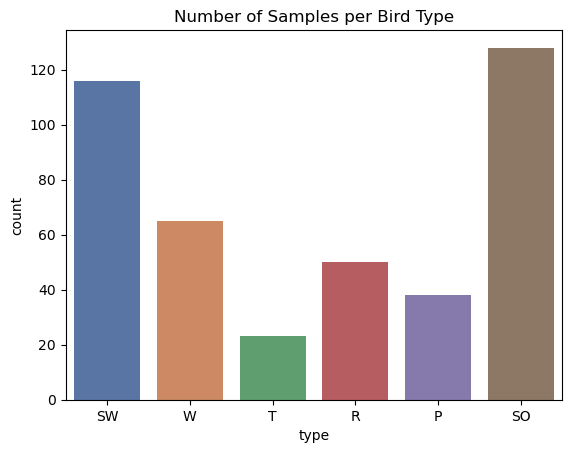

In [220]:
# Create a count plot showing the number of samples per bird type
sns.countplot(
    data=birds,
    x='type',
    hue='type',
    palette='deep',
    legend=False
)

plt.title('Number of Samples per Bird Type')
plt.savefig('countplot_bird_types.png', dpi=300, bbox_inches='tight')
plt.show()

#Feature Distribution

Histograms are used to examine the distribution shape of each skeletal measurement. The obtained histograms show that all skeletal measurements exhibit a right-skewed (positively skewed) distribution, meaning that most values are relatively small, with fewer large values. For example, the humerus length (huml) has most samples below 100 mm, with only a few exceeding 300 mm. This skewness indicates that the features are not normally distributed, which may affect the performance of algorithms sensitive to data distributions. Consequently, feature scaling, such as standardisation or normalisation, is required prior to training. 

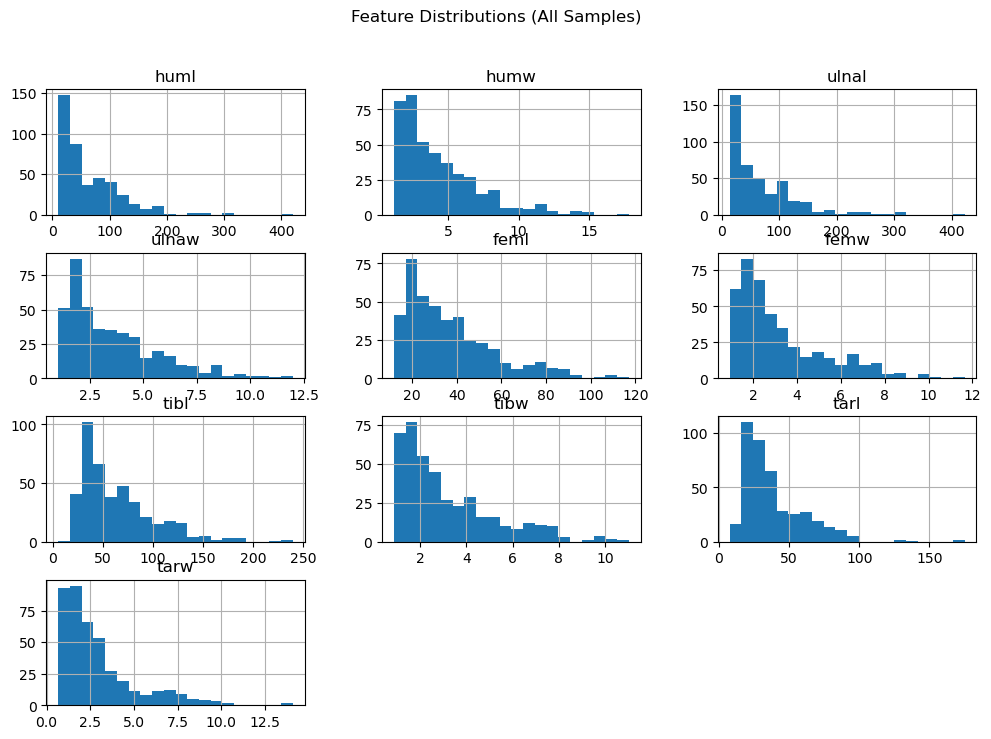

In [215]:
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=plt.cm.tab10.colors)
# Create histograms for all numerical features
# Drop 'id' column as it's just an identifier, not a feature
birds.drop(columns=['id']).hist(figsize=(12,8), bins=20)
plt.suptitle('Feature Distributions (All Samples)')
plt.savefig("feature_distributions.png", dpi=300, bbox_inches='tight')
plt.show()

#Boxplots by Class

Boxplots are used in our EDA to visualise the distribution, variability, and presence of outliers within our features across different bird classes. Noticeable differences in skeletal measurements across bird groups are observed. Swimming birds (SW), Wading birds (W), and Raptors (R) tend to exhibit larger bone lengths and widths with higher variability. In contrast, Terrestrial birds (T) and Scansorial birds (P) generally show smaller and narrower skeletal measurements with lower variability, while Singing birds (SO) display moderate values and variability. Outliers are present across all classes, particularly among Swimming (S) and wading (W) birds, indicating individual specimens with unusually large bones. These observed variations further confirm that skeletal measurements provide strong discriminatory power for the bird classification task.

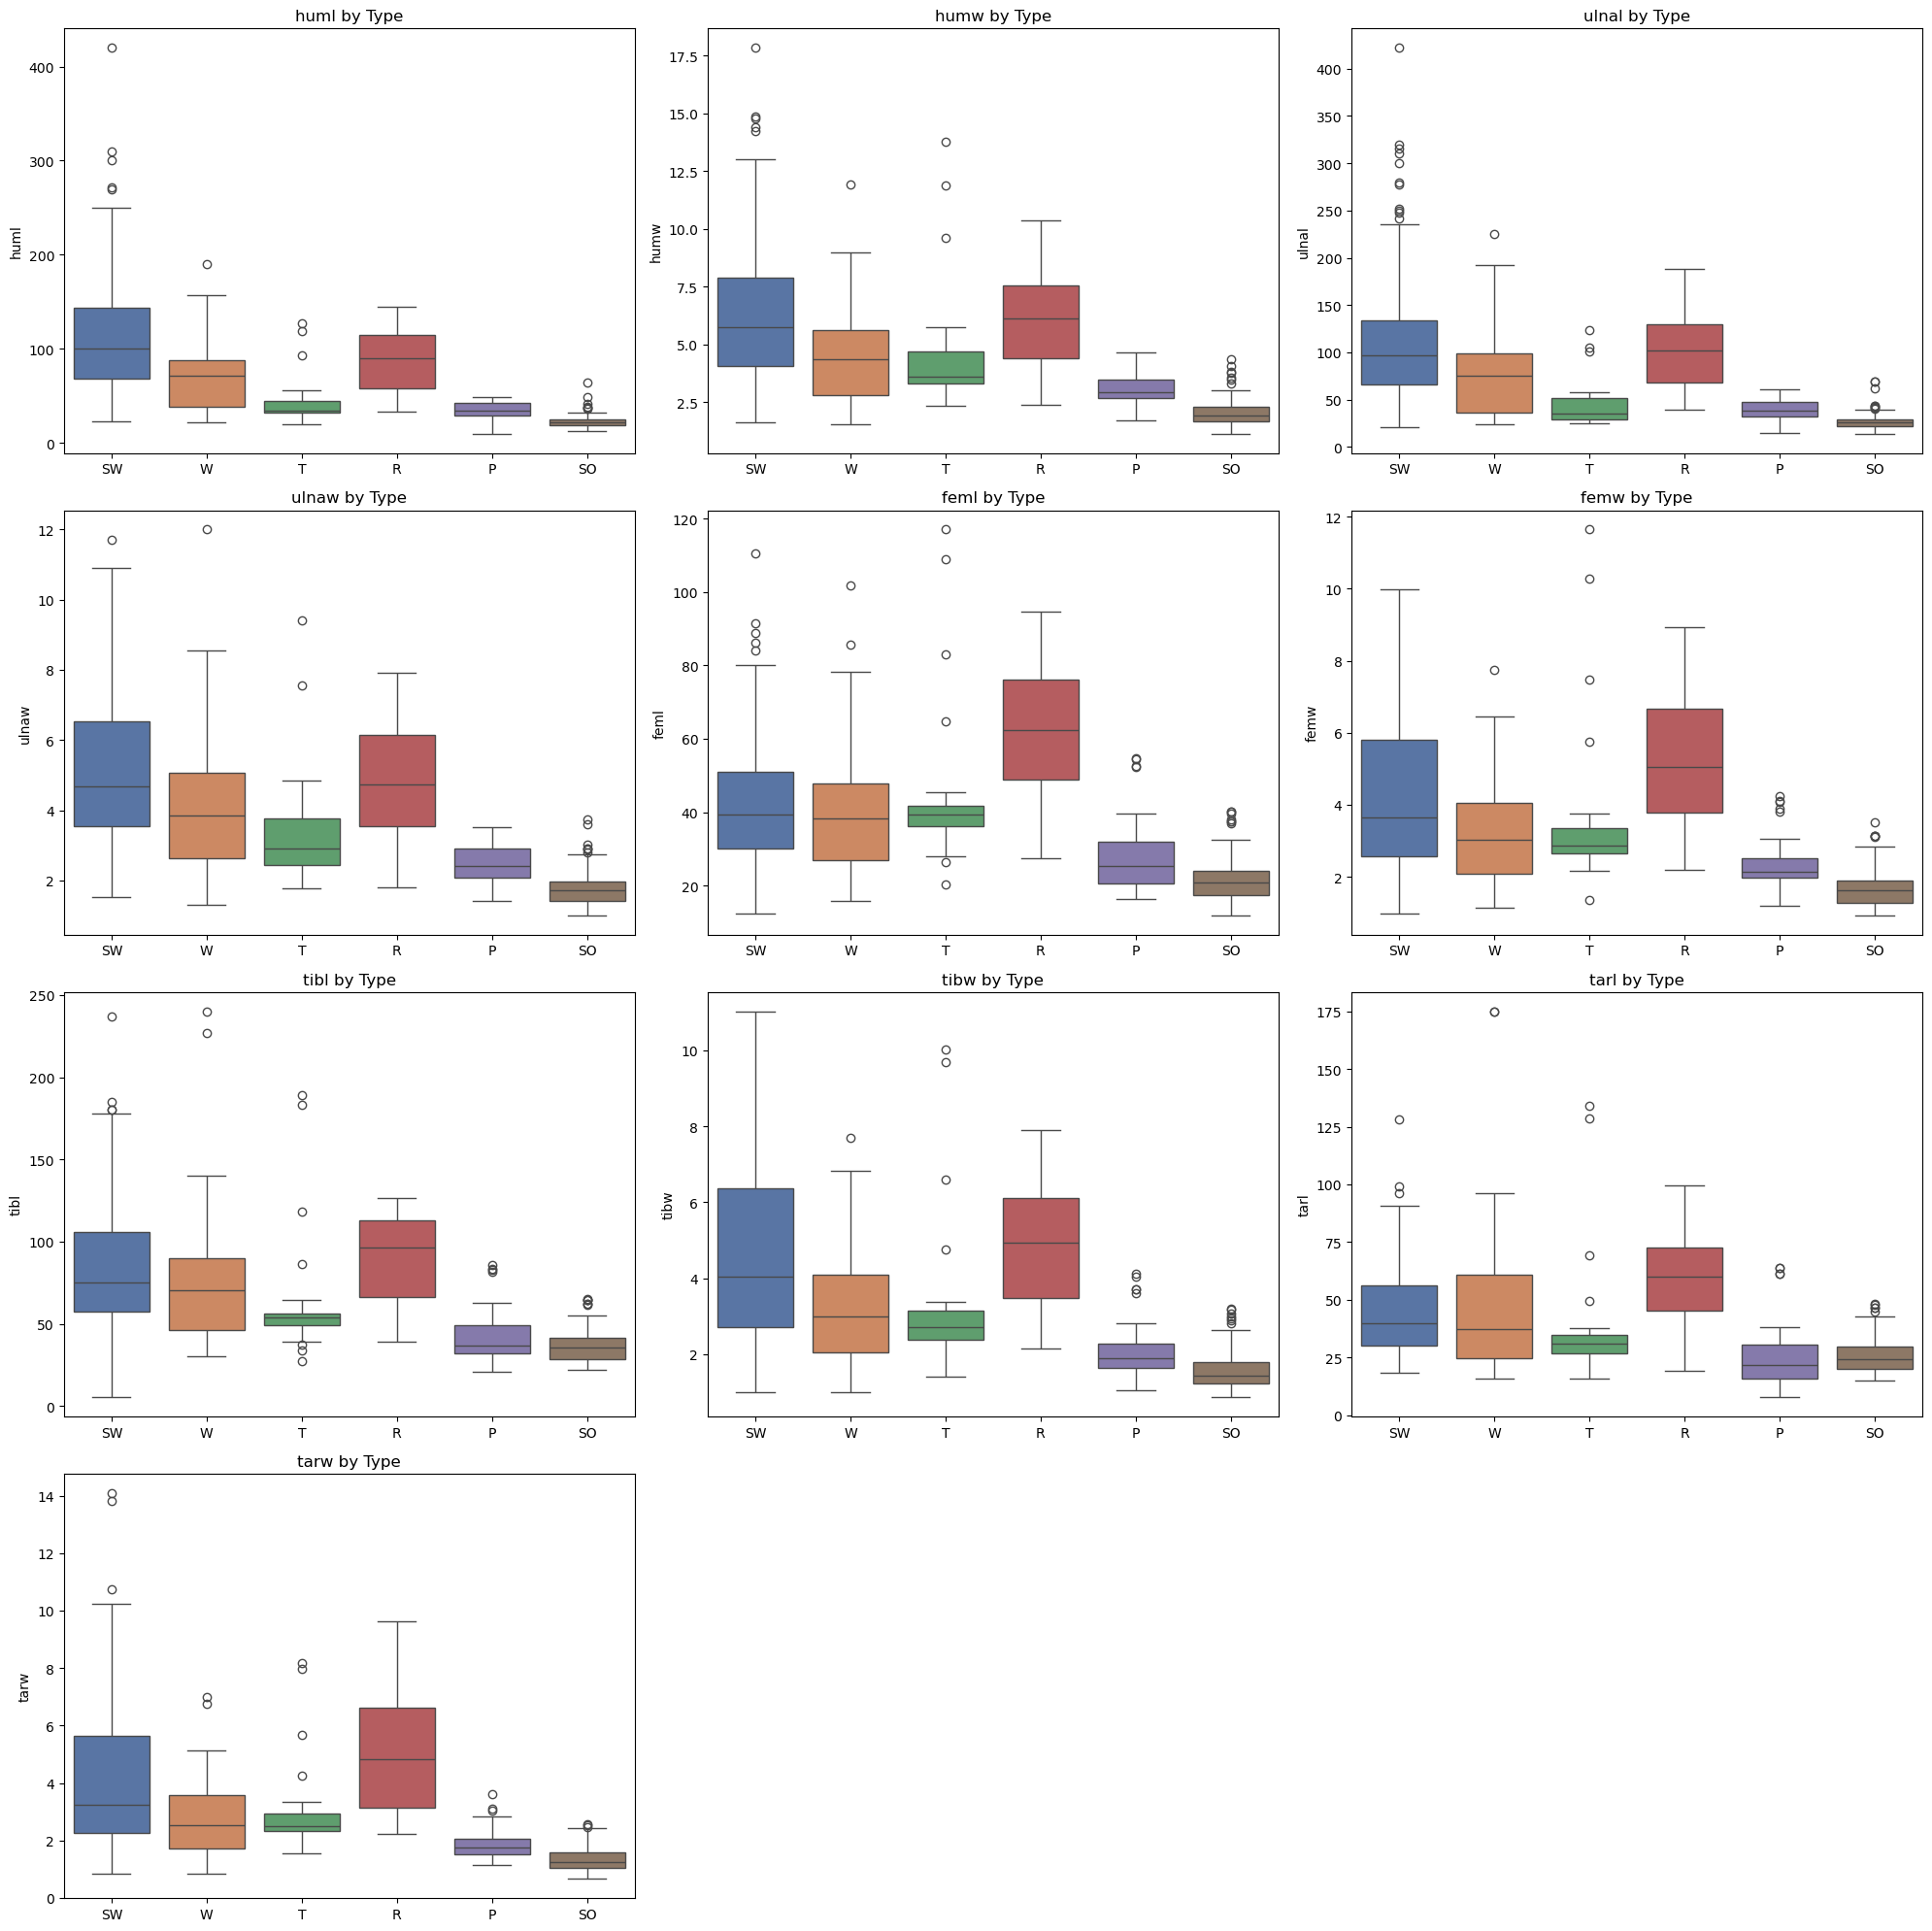

In [222]:
features = birds.drop(columns=['id', 'type']).columns

# Number of rows needed
n_cols = 3
n_rows = (len(features) + n_cols - 1) // n_cols

plt.figure(figsize=(20, 20))

for i, col in enumerate(features, 1):
    plt.subplot(n_rows, n_cols, i)
    sns.boxplot(
        data=birds,
        x='type',
        y=col,
        hue='type',
        palette='deep',
        legend=False
    )
    plt.title(f"{col} by Type")
    plt.xlabel("")
    plt.ylabel(col)

plt.tight_layout()
plt.savefig("boxplots_by_type.png", dpi=300, bbox_inches='tight')
plt.show()

#Pairplot for Feature Relationships

In order to examine relationships between skeletal measurements and class separability, pair plots are generated. The diagonal plots show the distribution of individual features, while the off-diagonal plots display scatter plots of feature pairs coloured by bird type. Strong positive correlations are observed among many features, which is expected as birds with larger bones tend to have larger skeletal measurements overall. Some overlap between classes is also visible, indicating potential challenges for certain classifiers and highlighting the need for models capable of handling complex feature relationships.


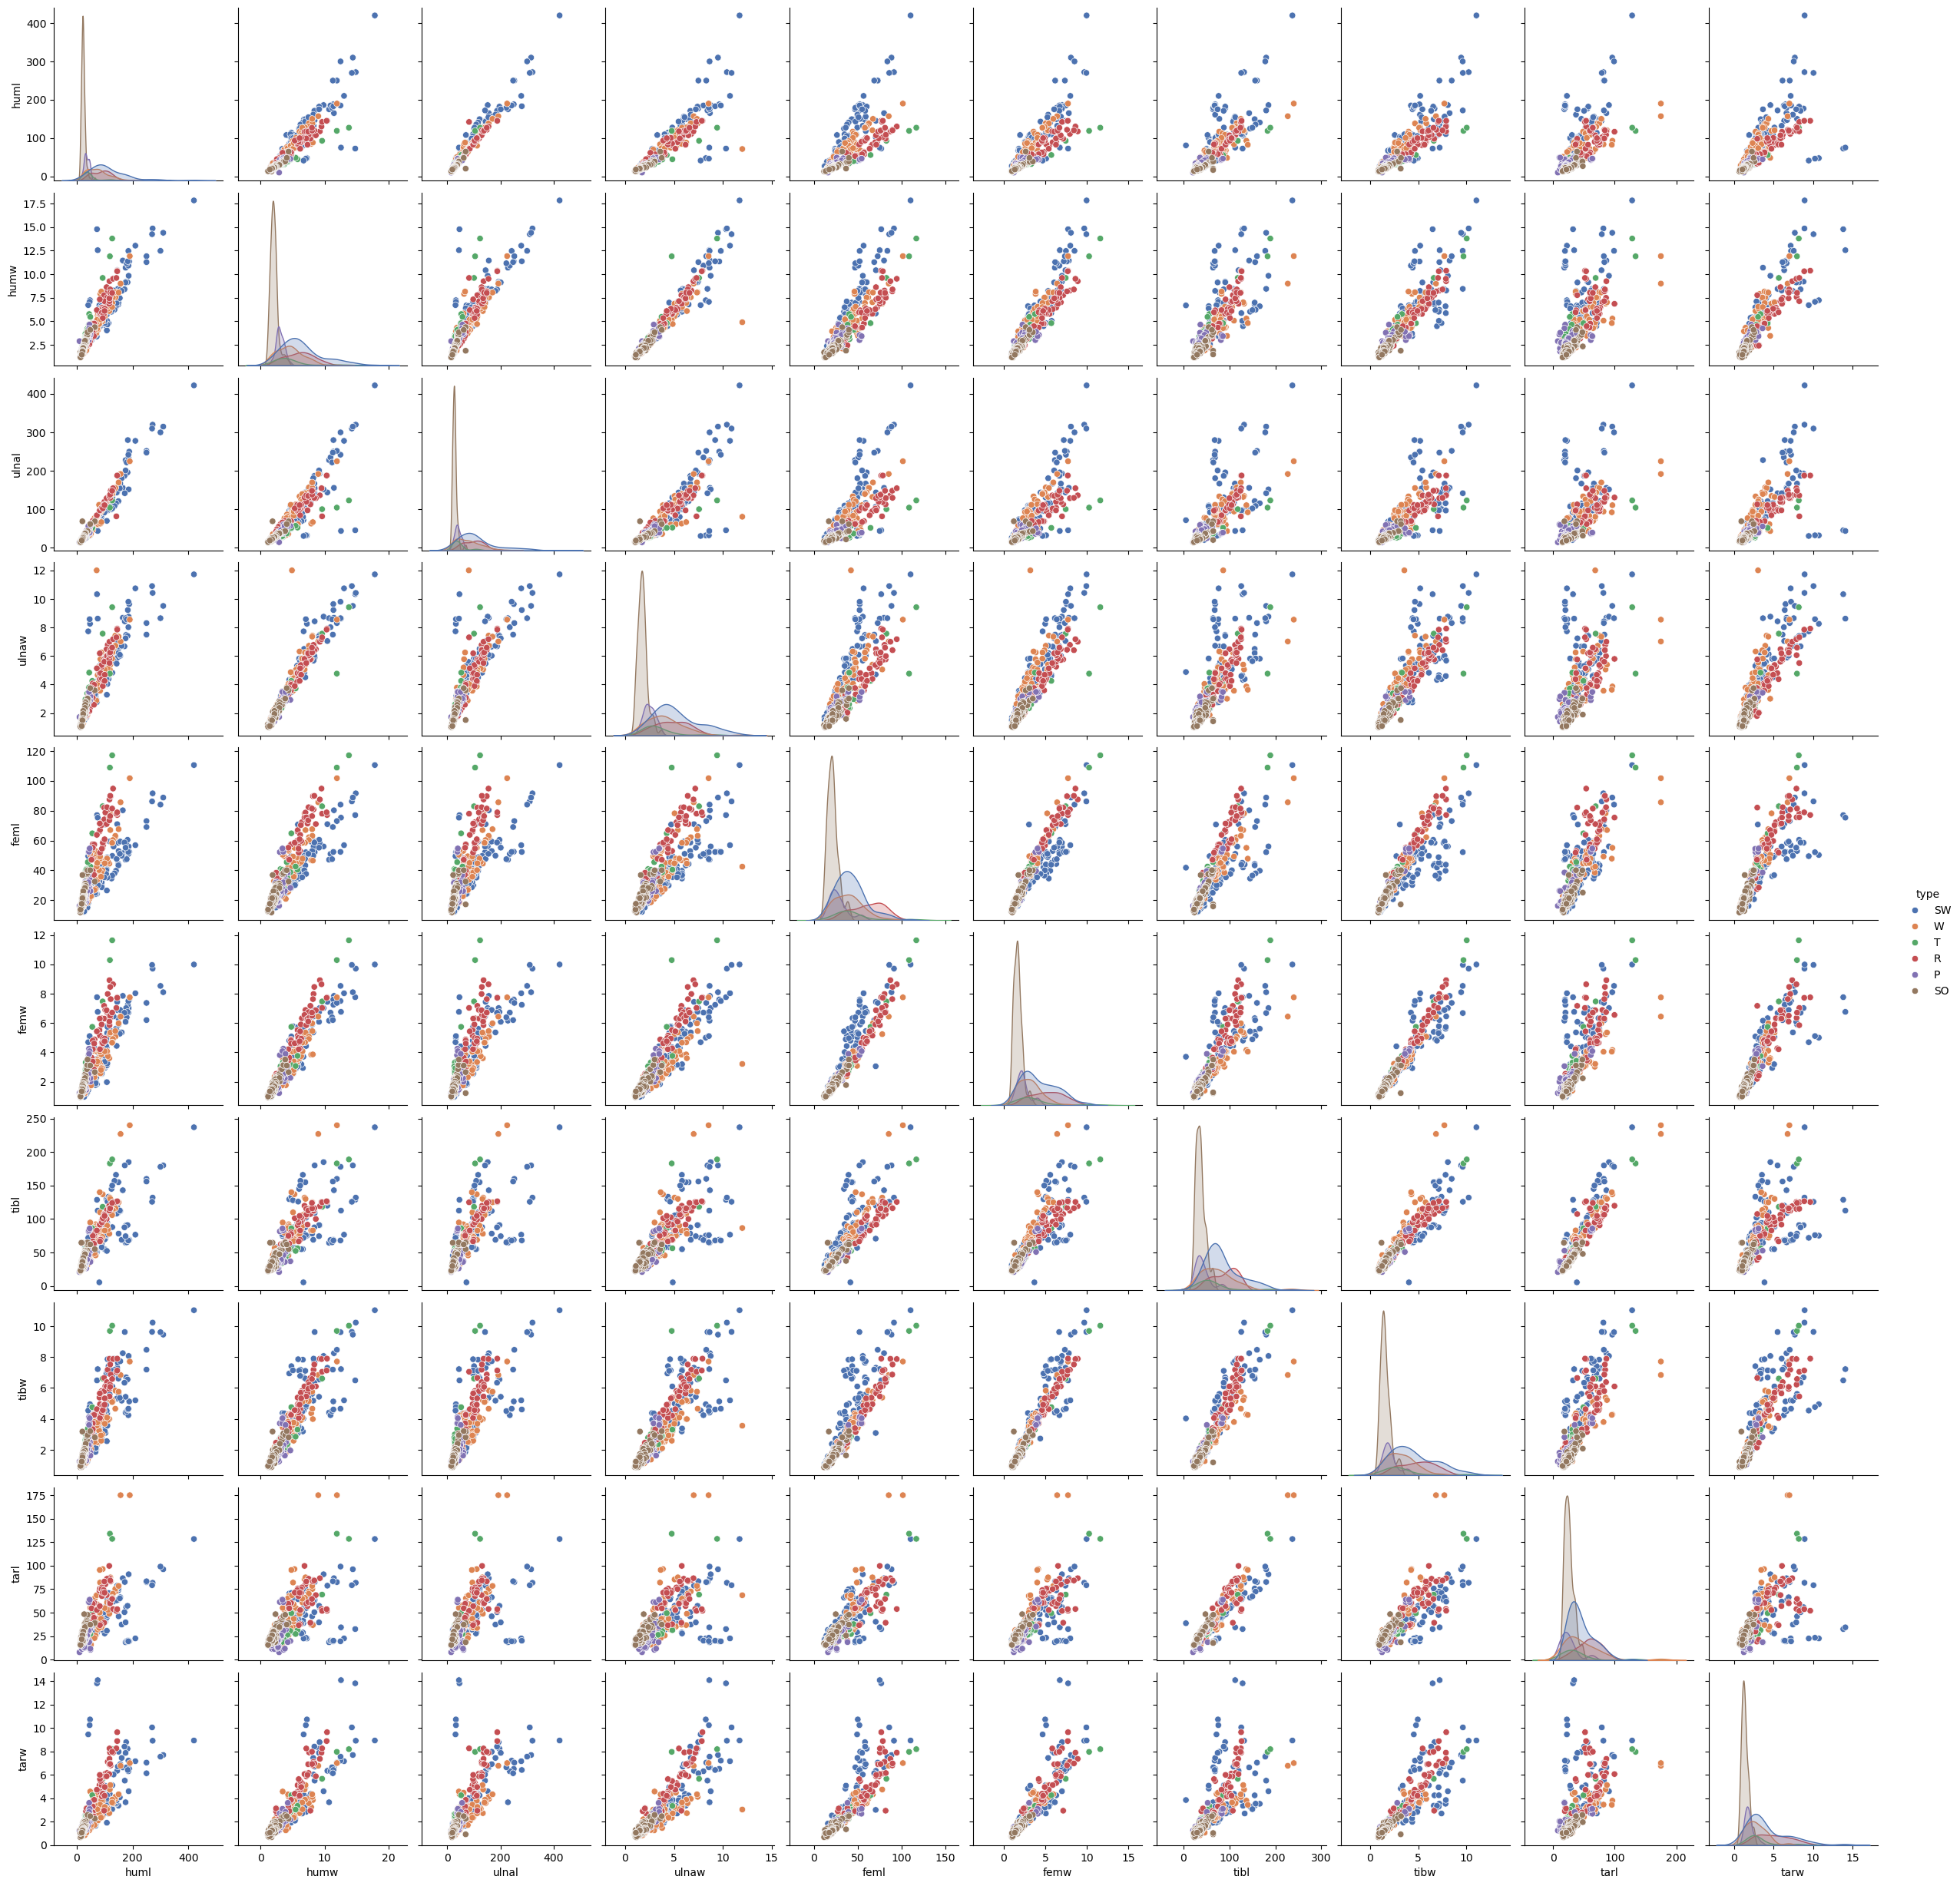

In [223]:
# Create pairplot for all features excluding 'id' as it is not a feature 
sns.pairplot(
    birds.drop(columns=['id']),
    hue="type",
    palette="deep",
    diag_kind="kde"
)

plt.savefig("pairplot_bird_types.png", dpi=300, bbox_inches='tight')
plt.show()

#Correlation Heatmap

Linear relationships between skeletal measurements and potential feature redundancy are identified using a correlation matrix visualised through a heatmap.
This heatmap displays the correlation coefficients between features, where colour intensity represents the strength of the correlation, with warmer colours indicating stronger positive relationships.

The results confirm the observations from the pair plots, showing that most skeletal measurements are highly correlated, with many correlation coefficients exceeding 0.8. For example, humerus length (huml) and ulna length (ulnal) exhibit a very strong positive correlation, as do femur width (femw) and tibia width (tibw). These strong correlations are biologically expected, as birds with larger bodies tend to have proportionally larger skeletal structures. However, the presence of high correlations also suggests potential redundancy among features, which may affect certain machine learning models and should be considered during feature selection or model choice.

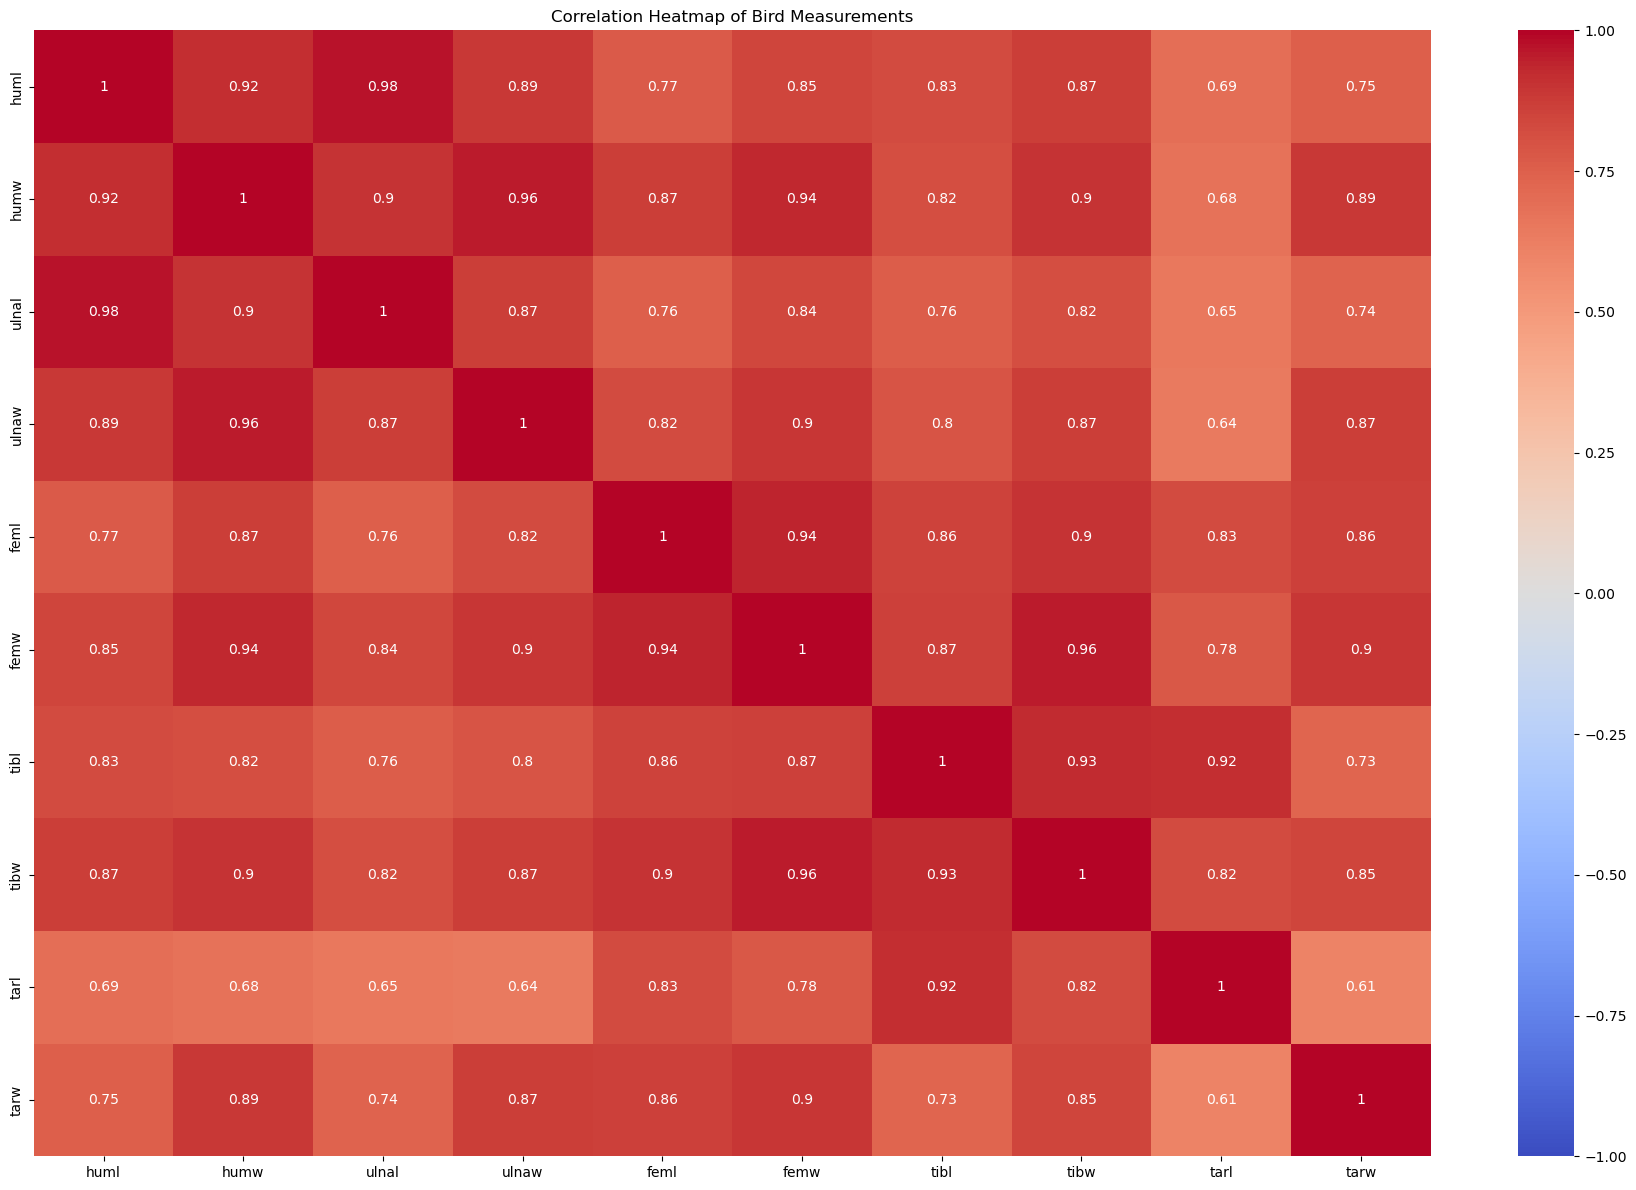

In [225]:
# Calculate correlation matrix for all numerical features
# Exclude 'id', which is not a feature, and 'type`(categorical varaiable) 
corr = birds.drop(columns=['id', 'type']).corr()

plt.figure(figsize=(18, 12))


sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)

plt.title('Correlation Heatmap of Bird Measurements')
plt.tight_layout()

# Save the heatmap
plt.savefig("Correlation_Heatmap_without_ID.png", dpi=300)

plt.show()

#Mutual Information Feature Importance

As a final step in our EDA section, feature importance is assessed using Mutual Information (MI) to measure how informative each skeletal measurement is for predicting the bird type. Mutual Information quantifies the dependency between features and the target variable and is useful because it captures both linear and non-linear relationships without assuming any specific data distribution.

As illustrated in the obtained plot, the humerus length (huml) carries the highest amount of information about the bird class, with a mutual information score of approximately 0.63. This is followed by ulna length (ulnal) and humerus width (humw), indicating that these features are highly informative for the classification task. In contrast, features such as tarsus length (tarl) and femur length (feml) exhibit lower mutual information scores, suggesting a smaller contribution to class prediction. This analysis highlights which skeletal measurements are most relevant and guides feature selection and model development, with final importance validated during the training phase.

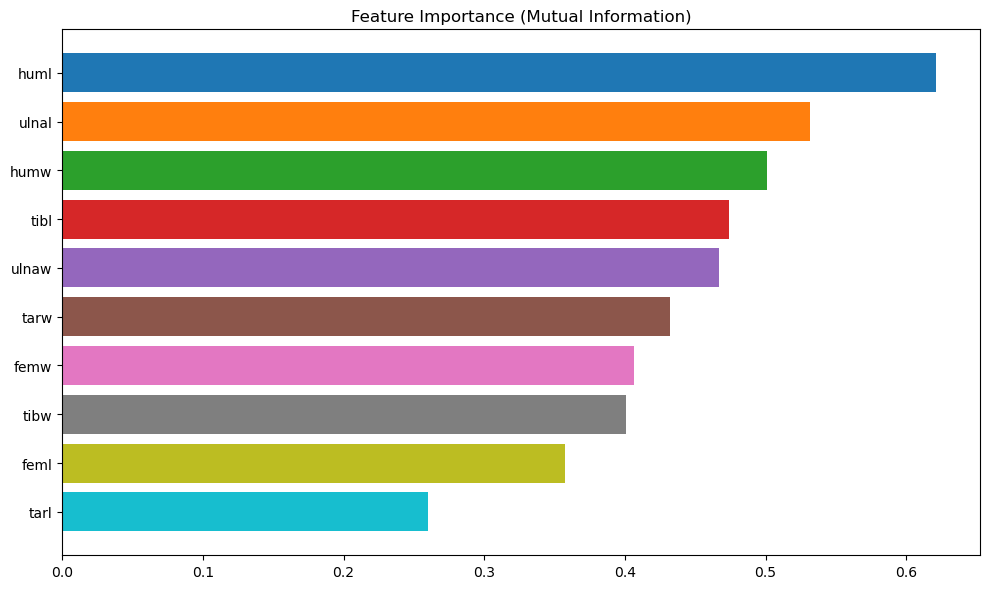

In [226]:
from sklearn.feature_selection import mutual_info_classif 
X= birds.drop(columns=['id','type'], errors='ignore')
y = birds['type']

mi = mutual_info_classif(X, y, random_state=0)
mi = pd.Series(mi, index=X.columns).sort_values(ascending=False)

colors = ["#1f77b4","#ff7f0e","#2ca02c","#d62728","#9467bd",
          "#8c564b","#e377c2","#7f7f7f","#bcbd22","#17becf"]

plt.figure(figsize=(10,6))
plt.barh(mi.index, mi.values, color=colors[:len(mi)])
plt.gca().invert_yaxis()
plt.title("Feature Importance (Mutual Information)")
plt.tight_layout()
plt.show()

The conducted exploratory data analysis revealed several key characteristics of our 'bird.csv' dataset, including class imbalance, skewed feature distributions, and strong correlations among skeletal measurements. Class imbalance may bias models toward majority classes, skewed distributions can affect algorithms sensitive to feature scaling and data normality, and high correlations between features indicate potential redundancy that may impact certain models. These limitations highlight the need for appropriate preprocessing and careful model selection before training.

# 3.Defining features and target variables

Before performing any train–test split or cross-validation, the dataset is divided into features, which are the independent variables and the target variable, which represents the dependent variable.
The feature matrix X contains all numerical skeletal measurements, excluding the id column, which serves only as an identifier, and the type column, which represents the class labels. The target variable y consists of the type column, which indicates the ecological class of each bird.

In [227]:
# Separate features (X) (Skeletal measurements) from target (y) (bird classes)
X ,y = birds.drop(columns=['id', 'type']), birds ['type']
print(f"X: {X.shape}")
print(f"y: {y.unique()}")

X: (420, 10)
y: ['SW' 'W' 'T' 'R' 'P' 'SO']


# 4.Feature Engineering and Selection

All ten skeletal measurements are retained for training. First, because mutual information analysis indicates that each feature provides useful information for predicting bird types, as all features exhibit positive mutual information scores. Although correlation analysis reveals strong relationships among several skeletal measurements, these relationships are biologically expected, since birds with larger bodies tend to have proportionally larger skeletal structures.
Moreover, as we have a relatively small number of features, removing any of them may result in the loss of informative biological patterns, so, instead of discarding features, appropriate preprocessing techniques will be applied to account for the relationships between features. Consequently, all skeletal measurements are retained, allowing each model to leverage the available information according to its learning mechanism.

# 5.Cross validation

Stratified K-Fold Cross-Validation is used instead of a single train/test split, given the relatively small dataset size (420 samples) and the presence of class imbalance. This approach preserves class proportion in each fold, provides more robust performance estimates, and allows all samples to be used for both training and testing. 

We first import `StratifiedKFold` from scikit-learn to implement our stratified k-fold cross-validation.


In [239]:
from sklearn.model_selection import StratifiedKFold 

5-fold stratified cross-validation is chosen, where the data is divided into five stratified folds. The model is trained on four folds (4/5 = 80% = 336 samples) and evaluated on the remaining fold (1/5 = 20% = 84 samples), rotating through all folds, and final performance metrics are averaged across all iterations. Stratified sampling ensures each fold has the same class distribution as the full dataset.
 
**Why 5 folds?** 5-folds are chosen as they provide an optimal balance between computational efficiency and robust evaluation, ensuring that even our smallest class (Terrestrial: 23 samples) has approximately 4-5 samples per test fold (20% of 23), sufficient for reliable evaluation.

In [241]:
# Create stratified 5-fold cross-validator
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42) 

# 6.Models training and evaluation

In this section, three machine learning models, Random Forest, Support Vector Machine **(SVM)**, and K-Nearest-Neighbour **(KNN)** are trained and compared to see their effectiveness in our given task. Each model is first tested with default parameters to establish baseline performance, and after which hyperparameters are tuned using the GridSearchCV, aiming to improve the results. The model's performance is assessed using 5-fold cross-validation and evaluated using multiple metrics, including accuracy, confusion matrix, sensitivity, specificity, ROC curves, and AUC scores. Finally, feature importance is analysed to identify which skeletal measurements contribute most to the classification task, and validate the findings revealed by the feature importance using mutual information analysis conducted during our EDA section.

**6.1 Random Forest Classifier**

The first model to be trained and evaluated is the Random Forest Classifier. 

Random Forest is an ensemble learning method that combines multiple decision trees to make predictions. Each tree in the forest is trained on a random subset of the data, and the final prediction is made by majority voting across all trees.  

Random Forest is chosen as the main model because it handles non-linear relationships between features, naturally provides feature importance rankings, performs well with imbalanced datasets.In addition, it is robust to outliers and noise, reduces the risk of overfitting through ensemble learning, and generally delivers stable and reliable performance.

`Model with Default Parameters`

We first begin by training a Random Forest classifier **rf** using default parameters from scikit-learn to establish a baseline performance benchmark.  

In [292]:
from sklearn.ensemble import RandomForestClassifier

In [249]:
# Initialize Random Forest with default parameters
# random_state=42 ensures reproducibility of results
rf = RandomForestClassifier(random_state=42)

`Evaluating performance using cross validation`

We evaluate our  Random Forest model **rf** using stratified 5-fold cross-validation to get a reliable estimate of its performance with default parameters. This gives us one accuracy score per fold fold resulting in a total of five accuracy scores, which are averaged to get the overall baseline performance.

In [252]:
from sklearn.model_selection import cross_val_score 

In [253]:
# Evaluate Random Forest using 5-fold cross-validation
scores = cross_val_score(rf, X, y, cv=cv, scoring="accuracy")
print("Cross-Validation Accuracy per fold:", scores)
print("Mean Accuracy:" ,scores.mean())

Cross-Validation Accuracy per fold: [0.83333333 0.89285714 0.80952381 0.85714286 0.8452381 ]
Mean Accuracy: 0.8476190476190476


Our Random Forest classifier **rf**  with default parameters achieves a mean cross-validation accuracy of **84.76%** across all five folds. The accuracy ranges from **80.95%** to **89.29%**, showing relatively consistent performance across different data splits. Despite this baseline performance, hyperparameter tuning will be applied to further improve the model’s results and identify the optimal hyperparameter combination. 

` Hyperparameters tuning with GridSearchCV`

To improve upon our baseline performance, we will use **GridSearchCV** to systematically search for the optimal hyperparameter combination. GridSearchCV exhaustively tests all possible combinations of specified parameters using cross-validation.

We will tune seven key parameters with randomly selected value ranges: 

**n_estimators** [100, 200, 300, 400, 500]: controls the number of trees in the forest, where more trees generally improve performance but increase computation time.

**max_depth** [12, 16, None]: sets the maximum depth of each tree, where None means unlimited depth; however, deeper trees risk overfitting.

**max_features** ['sqrt', 'log2', None]: determines the number of features considered at each split to reduce correlation between trees.

**min_samples_split** [2, 4]: sets the minimum samples required to split a node, where higher values prevent overfitting. 

**min_samples_leaf** [1, 2]: defines the minimum samples in leaf nodes, where higher values create smoother decision boundaries. 

**bootstrap** [True, False]: determines whether to use bootstrap sampling, where True represents standard Random Forest behaviour.

**class_weight** [None, 'balanced']: handles class imbalance by adjusting weights inversely proportional to class frequencies.

This creates a search space of 5 × 3 × 3 × 2 × 2 × 2 × 2 = **720** combinations, which when combined with 5-fold cross-validation results in **3,600** total model trainings.

In [254]:
from sklearn.model_selection import GridSearchCV 
# Define the parameter grid to search
param_grid = {
    "n_estimators": [100, 200, 300, 400,500],
    "max_depth": [12, 16, None],
    "max_features": ["sqrt", "log2",None],
    "min_samples_split": [2, 4],
    "min_samples_leaf": [1, 2],
    "bootstrap": [False, True], 
    "class_weight": [None, "balanced"],
}

# Initialise GridSearchCV
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,          
    n_jobs=-1,       
    verbose=1        
)

# Fit GridSearch - this will take time (3,600 model fits!)
grid_search.fit(X, y)

# Extract the best model found
best_rf_grid = grid_search.best_estimator_
# Print best parameters and performance
print("\nBest Params (Grid Search):", grid_search.best_params_)
print("Best Mean CV Accuracy:", round(grid_search.best_score_, 4))

# Evaluate the tuned model using cross-validation
scores = cross_val_score(best_rf_grid, X, y, cv=cv, scoring="accuracy", n_jobs=-1)
print("Tuned Model - CV Accuracies:", scores)
print("Tuned Model - Mean CV Accuracy:", round(scores.mean(), 4))



Fitting 5 folds for each of 720 candidates, totalling 3600 fits

Best Params (Grid Search): {'bootstrap': False, 'class_weight': 'balanced', 'max_depth': 16, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Best Mean CV Accuracy: 0.8524
Tuned Model - CV Accuracies: [0.82142857 0.85714286 0.8452381  0.85714286 0.88095238]
Tuned Model - Mean CV Accuracy: 0.8524


The grid search identified the following as best parameters: bootstrap=False, class_weight='balanced', max_depth=16, max_features='sqrt', min_samples_leaf=1, min_samples_split=2, and n_estimators=100. 

Our tuned model **best_rf_grid** achieved a mean cross-validation accuracy of **85.24%**, resulting in a modest improvement of **0.48%** over the baseline model, with individual fold accuracies ranging from **82.14%** to **88.10%**.This small improvement suggests that Random Forest's default hyperparameters were already well-suited to this dataset, demonstrating the algorithm's robustness and indicating that the baseline model had already captured most of the predictive signal available in the features. 

The main contribution of tuning was the addition of class_weight='balanced' to better handle any class imbalance, and the constraint of max_depth=16 to potentially improve generalisation. This finding validates that further significant performance gains would likely require additional data or exploring alternative models rather than extensive hyperparameter optimisation.

`Model Evaluation Metrics`

To assess our tuned  Random Forest model's performance, all the required classification metrics including the confusion matrix (visualizing correct and incorrect classifications), sensitivity/recall (ability to identify positive cases), specificity (ability to identify negative cases), precision (proportion of correct positive predictions), F1-score (harmonic mean of precision and recall), ROC curves (trade-off between true and false positive rates), and AUC scores (overall discrimination ability).

Since 5-fold stratified cross-validation is used instead of a single train/test split, we employ **cross_val_predict** to generate out-of-fold (OOF) predictions. Each prediction is made when the sample is part of the test fold and unseen during model training.This provides predictions for all 420 samples while maintaining proper separation between training and testing data,resulting in a reliable evaluation of model performance.


`Classification report and Confusion matrix`

The classification report below provides detailed precision, recall, and F1-scores for each bird species class, while the confusion matrix visualises where the model makes correct predictions (diagonal elements) and where misclassifications occur (off-diagonal elements).


=== Classification Report (OOF via CV) ===
              precision    recall  f1-score   support

           P     0.8421    0.8421    0.8421        38
           R     0.8571    0.8400    0.8485        50
          SO     0.9124    0.9766    0.9434       128
          SW     0.8182    0.8534    0.8354       116
           T     0.9000    0.7826    0.8372        23
           W     0.7636    0.6462    0.7000        65

    accuracy                         0.8524       420
   macro avg     0.8489    0.8235    0.8344       420
weighted avg     0.8497    0.8524    0.8496       420



<module 'matplotlib.pyplot' from '/opt/anaconda3/envs/test/lib/python3.13/site-packages/matplotlib/pyplot.py'>

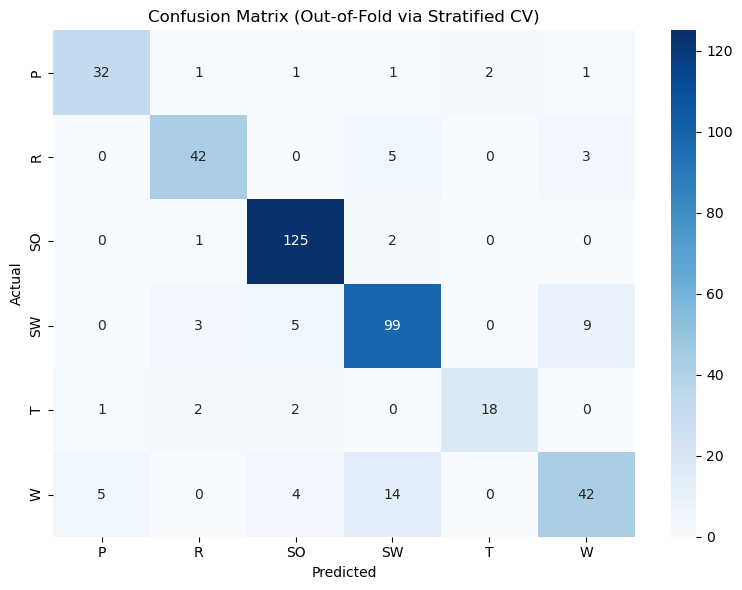

In [258]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix
y_pred_oof = cross_val_predict(best_rf_grid, X, y, cv=cv, n_jobs=-1)

print("\n=== Classification Report (OOF via CV) ===")
print(classification_report(y, y_pred_oof, digits=4))

labels = np.unique(y)
cm = confusion_matrix(y, y_pred_oof, labels=labels)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix (Out-of-Fold via Stratified CV)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt



The out-of-fold predictions achieve an overall accuracy of **85.24%**, with performance varying across bird species. Singing birds (SO) demonstrate the strongest performance with 91.24% precision, 97.66% recall, and 94.34% F1-score, correctly classifying 125 of 128 samples. Terrestrial birds (T) show high precision (90.00%) but lower recall (78.26%), while Raptors (R), Scansorial birds (P), and Swimming birds (SW) achieve balanced performance in the 81-86% range. Wadding birds (W) present the most challenging class with 76.36% precision and only 64.62% recall, with 14 instances misclassified as SW. The confusion matrix reveals that most errors occur between SW and W (23 total misclassifications), suggesting these species share similar visual or behavioural features that make discrimination more difficult. The macro average F1-score of 83.44% and weighted average of 84.96% demonstrate solid performance across all classes despite class imbalance.

`Specificity`

Specificity measures how well the model correctly identifies samples that do not belong to a given class by counting true negatives. It is calculated as the proportion of true negatives among all samples that are actually not in the class **Specificity = True Negatives / (True Negatives + False Positives)**,where True Negatives (TN) represent samples correctly predicted as not belonging to the class, and False Positives (FP) represent samples from other classes incorrectly predicted as belonging to this class.A high specificity indicates that the model rarely misclassifies other classes as the target class.

In [262]:
print("\n=== Specificity by Class (Random Forest) ===")
for i, class_label in enumerate(labels):
    # True Negatives: 
    tn = np.sum(cm) - (np.sum(cm[i, :]) + np.sum(cm[:, i]) - cm[i, i])
    
    # False Positives: 
    fp = np.sum(cm[:, i]) - cm[i, i]
    
    # Calculate specificity
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    print(f"{class_label}: {specificity:.4f}")


=== Specificity by Class (Random Forest) ===
P: 0.9843
R: 0.9811
SO: 0.9589
SW: 0.9276
T: 0.9950
W: 0.9634


All six bird species classes demonstrate excellent specificity scores, ranging from 92.76% to 99.50%: Terrestrial birds (T) achieves the highest at 99.50%, indicating the model rarely misclassifies other species as Terrestrial birds, followed by Scansorial birds (P) at 98.43%, Raptors (R) at 98.11%, Wading birds (W) at 96.34%, Singing birds (SO) at 95.89%, and Swimming birds (SW) at 92.76%. 

The slightly lower specificity for SW reflects the confusion with W class observed in the confusion matrix, where some samples from other species were misclassified as Swimming birds. 

These high specificity scores across all classes indicate that the model maintains strong discriminative ability and rarely produces false positive predictions, complementing the recall scores to provide a complete picture of classification performance.

`ROC Curves and AUC`

**ROC (Receiver Operating Characteristic) curve** is a graphical tool used to evaluate a classifier’s performance by showing how well it distinguishes between classes at different decision thresholds. In multi-class problems, a One-vs-Rest (OvR) approach is used, where each class is compared against all other classes. For each class, the ROC curve plots the True Positive Rate (Recall) on the y-axis against the False Positive Rate on the x-axis, illustrating the trade-off between correctly identifying the target class and incorrectly classifying other classes as that class.

**AUC (Area Under the Curve)** measures the overall performance of a classifier across all decision thresholds. An AUC of 1.0 indicates perfect classification, while an AUC of 0.5 corresponds to random guessing. Higher AUC values represent better performance, with values above 0.9 considered excellent, 0.8–0.9 good, and 0.7–0.8 acceptable. In multi-class classification, each bird class has its own ROC curve and corresponding AUC score using a One-vs-Rest approach.


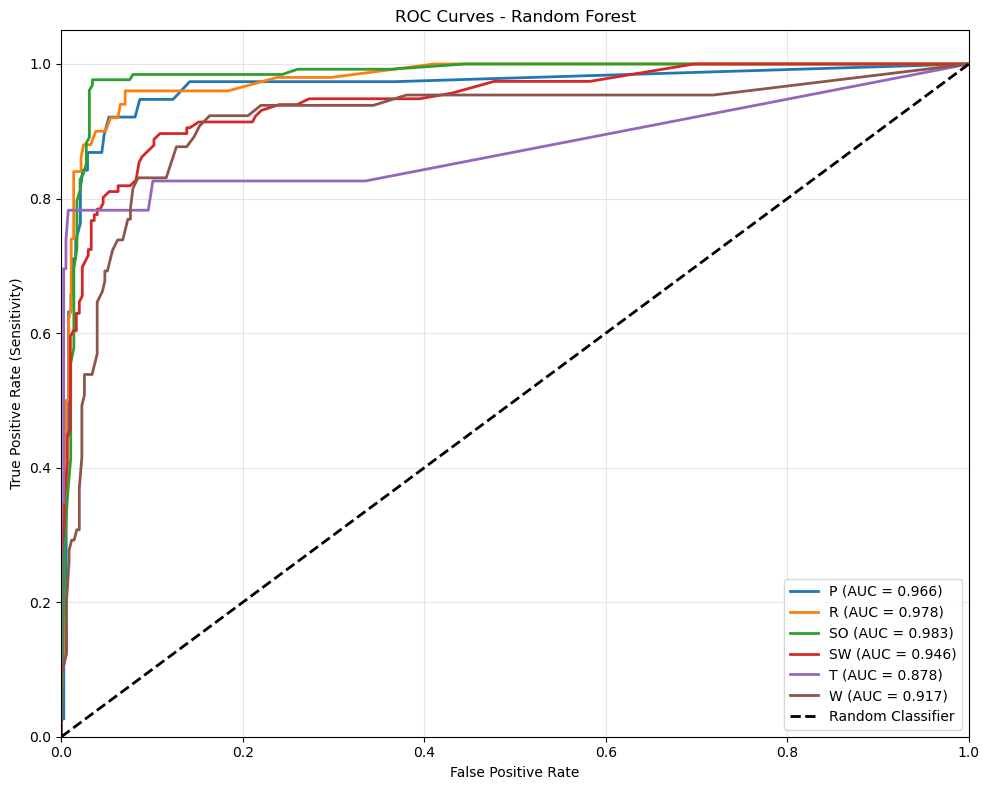


=== AUC Scores (Random Forest) ===
P: 0.9661
R: 0.9783
SO: 0.9829
SW: 0.9459
T: 0.8783
W: 0.9167
Macro-average AUC: 0.9447


In [266]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

y_pred_proba = cross_val_predict(best_rf_grid, X, y, cv=cv, 
                                  method='predict_proba', n_jobs=-1)

# Converts multi-class to binary One-vs-Rest format
y_bin = label_binarize(y, classes=labels)

# Create figure for ROC curves
plt.figure(figsize=(10, 8))
auc_scores = []

# Calculate ROC curve for each class
for i, class_label in enumerate(labels):
    fpr, tpr, thresholds = roc_curve(
        y_bin[:, i],           
        y_pred_proba[:, i]   
    )
    
    # Calculate AUC score
    roc_auc = auc(fpr, tpr)
    auc_scores.append(roc_auc)
    
    # Plot ROC curve
    plt.plot(fpr, tpr, lw=2, label=f'{class_label} (AUC = {roc_auc:.3f})')

# Plot diagonal line (random classifier baseline)
plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Random Classifier')

# Configure plot
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curves - Random Forest')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Print AUC scores
macro_auc = np.mean(auc_scores)  # Average across all classes
print("\n=== AUC Scores (Random Forest) ===")
for class_label, auc_score in zip(labels, auc_scores):
    print(f"{class_label}: {auc_score:.4f}")
print(f"Macro-average AUC: {macro_auc:.4f}")

Our Random Forest model **best_rf_grid** shows strong discriminative performance in the multi-class task as it achieves a macro-average AUC of 94.47%. Moreover, individual class AUC scores range from 87.83% for Terrestrial birds (T) to 98.29% for Singing birds (SO), with five out of six classes exceeding an AUC of 0.9, indicating a good class separability. All ROC curves lie well above the random classifier baseline, demonstrating robust discrimination across all bird species, including the lowest-performing class, which still achieves good performance.

`Feature Importance analysis`

In order to deduce which skeletal measurements contributed the most to the bird species classification task, a feature importance analysis based on our trained random forest model **best_rf_grid**  is performed.

**Feature importance** in Random Forest is measured using **Gini Importance**, which quantifies how much each feature reduces classification uncertainty across all decision trees. Higher values indicate features that are more critical for distinguishing between bird species.

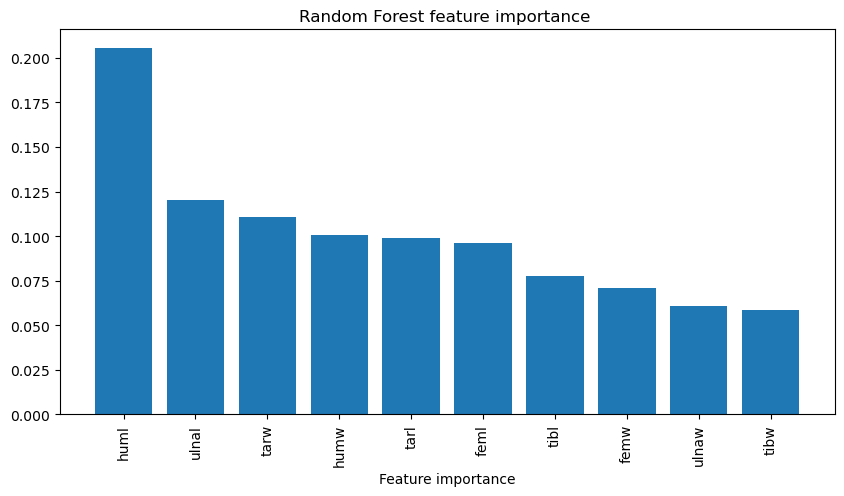

In [47]:
feature_importance = best_rf_grid.feature_importances_
feature_names = X.columns

sorted_indices = np.argsort(feature_importance)[::-1]
plt.figure(figsize=(10,5))
plt.bar(range(len(feature_importance)),feature_importance[sorted_indices],align="center")
plt.xticks(range(len(feature_importance)),np.array(feature_names)[sorted_indices], rotation=90)
plt.xlabel("Feature importance")
plt.title("Random Forest feature importance ")
plt.show()

The Random Forest feature importance analysis shows that humerus **length (huml)** is the most influential skeletal measurement for bird classification at 20.6%, followed by **ulna length (ulnal)** at 12.1% and **tarsus width (tatw)** at 11.1%. Several other measurements contribute moderately, with the remaining features ranging from 5.9% to 10.2%, indicating that classification relies on a combination of skeletal features rather than a single dominant one.

Compared with the earlier feature importance analysis based on Mutual Information, differences in feature rankings are observed due to Random Forest’s ability to account for feature interactions and redundancy within the ensemble context. Overall, the results highlight that multiple skeletal measurements jointly contribute to distinguishing bird species, reflecting the complex morphological adaptations across ecological groups (Swimming, Wading, Terrestrial, Raptors, Scansorial, and Singing birds).

**6.2 Support Vector Machine (SVM)**

The second model to be trained and evaluated is the Support Vector Machine (SVM). 

SVM is a supervised machine learning algorithm that finds the optimal hyperplane maximising the margin between different classes. It uses support vectors, which are the closest points to the decision boundary, to define the separation.

SVM is chosen as the second classifier because it performs well in high-dimensional feature spaces, such as our dataset with  10 skeletal measurements; moreover, it is effective at learning complex decision boundaries. Consequently, SVM can be a good complement to Random Forest by providing an alternative approach for separating classes in complex feature spaces. 


`Model with Default Parameters`

As with our previous RF model, we begin by training a Support Vector Machine (SVM) classifier using default parameters to establish a baseline performance benchmark. 

Our baseline SVM model **svm** is implemented using default parameters ( kernel= RBF (Radial Basis Function), regularisation parameter C=1.0, and gamma='scale').

Unlike random forest, which is scale invariant, SVM requires scaling as it is sensitive to the magnitude of input features. Therefore, **Pipeline** is used to combine feature standardisation and model training into a single workflow, which guarantees that scaling is applied consistently during training and evaluation, while preventing data leakage by ensuring that scaling parameters are learned only from the training data within each cross-validation fold.**StandardScaler** is used to normalise features by transforming them to have zero mean and unit variance, ensuring that all skeletal measurements contribute equally to the model and prevent features with larger numerical ranges from dominating the learning process. The **svm** classifier is then applied to the scaled data.

In [290]:
from sklearn.preprocessing import StandardScaler # Import StandardScaler to normalize features (mean=0, std=1)
from sklearn.pipeline import Pipeline # Import Pipeline to chain preprocessing and model steps together
from sklearn.svm import SVC
svm = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(random_state=42, probability=True))  
 # probability=True allows the computation of class probabilities, for  ROC curves and AUC scores. 
])


`Evaluating performance using cross validation`

We evaluate our baseline model **svm** using the same stratified 5-fold cross-validation applied previously for the Random Forest model. 

Since the cross-validation object and evaluation functions were already defined and imported earlier, there is no need to redefine them here. 

This procedure produces one accuracy score per fold, resulting in five accuracy values that are then averaged to obtain the overall baseline performance of the model using default parameters.


In [293]:
scores = cross_val_score(svm, X, y, cv=cv, scoring="accuracy")
print("SVM Baseline Cross-Validation Accuracy per fold:", scores)
print("Mean Accuracy:", scores.mean())

SVM Baseline Cross-Validation Accuracy per fold: [0.6547619  0.66666667 0.69047619 0.67857143 0.66666667]
Mean Accuracy: 0.6714285714285715


Our **svm** achieves a mean cross-validation accuracy of 67.14% across the five folds, where individual fold accuracies range from 65.48% to 69.05%, indicating relatively stable but lower performance across different data splits. This baseline result suggests that, while SVM can learn decision boundaries in the feature space, its default configuration is less effective compared to Random Forest. Consequently, hyperparameter tuning will be applied to improve the performance and assess whether better parameter settings can enhance the performance.

`Hyperparameters tuning with GridSearchCV`

The **svm** model is tuned using **GridSearchCV**, following the same stratified 5-fold cross-validation strategy described earlier for the Random Forest model; therefore, no additional imports or redefinition of the tuning procedure are required. 

The following key SVM hyperparameters are explored: 

**Regularisation parameter C** [100, 200, 300, 400, 500]: controls the trade-off between margin width and classification accuracy,with smaller values allowing a wider margin but may underfit, and larger values aim to correctly classify more training samples but may overfit.

**The kernel** [`rbf`, `poly`,`sigmoid`]: Defines the shape of the decision boundary, where different kernels allow the model to capture different types of relationships in the data.

**gamma** ['scale', 'auto', 0.001,0.01,0.1]: Determines the influence of individual training samples, where higher values lead to more complex decision boundaries, while lower values produce smoother boundaries.

**class_weight** [None, 'balanced']: handles class imbalance by adjusting weights inversely proportional to class frequencies.

This results in **120** hyperparameter combinations, which, when evaluated using 5-fold stratified cross-validation, gives a total of 600 model evaluations. 

After identifying the optimal configuration, the best model **best_svm** is re-evaluated using cross-validation, and out-of-fold predictions are generated using cross_val_predict for detailed performance analysis, including confusion matrix, classification report, and ROC/AUC evaluation.

In [294]:
# Define parameter grid for SVM
param_grid_svm = {
    'svm__C': [0.1, 1, 10, 100],
    'svm__kernel': ['rbf', 'poly', 'sigmoid'],
    'svm__gamma': ['scale', 'auto', 0.001, 0.01, 0.1],
    'svm__class_weight': [None, 'balanced']
}
# GridSearchCV for SVM
print("\nStarting GridSearchCV for SVM...")
grid_search_svm = GridSearchCV(
    estimator=svm,
    param_grid=param_grid_svm,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1,
    verbose=1
)
# Fit GridSearch (600 model fits!)
grid_search_svm.fit(X, y)

# Best model
best_svm = grid_search_svm.best_estimator_
print("\nBest Params (SVM):", grid_search_svm.best_params_)
print("Best Mean CV Accuracy:", round(grid_search_svm.best_score_, 4))

# Cross-validation with best model
scores = cross_val_score(best_svm, X, y, cv=cv, scoring="accuracy", n_jobs=-1)
print("Tuned SVM - CV Accuracies:", scores)
print("Tuned SVM - Mean CV Accuracy:", round(scores.mean(), 4))

# Get out-of-fold predictions for detailed evaluation
y_pred_svm = cross_val_predict(best_svm, X, y, cv=cv, n_jobs=-1)



Starting GridSearchCV for SVM...
Fitting 5 folds for each of 120 candidates, totalling 600 fits

Best Params (SVM): {'svm__C': 100, 'svm__class_weight': 'balanced', 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
Best Mean CV Accuracy: 0.8905
Tuned SVM - CV Accuracies: [0.9047619  0.89285714 0.83333333 0.9047619  0.91666667]
Tuned SVM - Mean CV Accuracy: 0.8905


Our tuned SVM model **best_svm** achieved a mean cross-validation accuracy of **89.05%**, representing a great improvement over its baseline performance of **67.14%**. 

Compared to the Random Forest model, which achieved a mean cross-validation accuracy of **85.24%** with an improvement of 0.48% only over the baseline model, the Support Vector Machine demonstrates a greater benefit from hyperparameter tuning with an improvement of **21.91%**. While Random Forest's minor performance improvement indicates that its default parameters were already well-suited to the dataset, reflecting its robustness and stability, the SVM shows a more substantial improvement after tuning, suggesting that SVM is more sensitive to hyperparameter selection on this dataset and ultimately achieves superior classification performance.

`Classification report and Confusion matrix`

The following classification report and confusion matrix are presented to analyse the performance of the tuned SVM model across individual bird species and to identify remaining patterns of misclassification.


=== Classification Report (SVM OOF via CV) ===
              precision    recall  f1-score   support

           P     0.7619    0.8421    0.8000        38
           R     0.9000    0.9000    0.9000        50
          SO     0.9466    0.9688    0.9575       128
          SW     0.9115    0.8879    0.8996       116
           T     0.8182    0.7826    0.8000        23
           W     0.8387    0.8000    0.8189        65

    accuracy                         0.8905       420
   macro avg     0.8628    0.8636    0.8627       420
weighted avg     0.8909    0.8905    0.8903       420



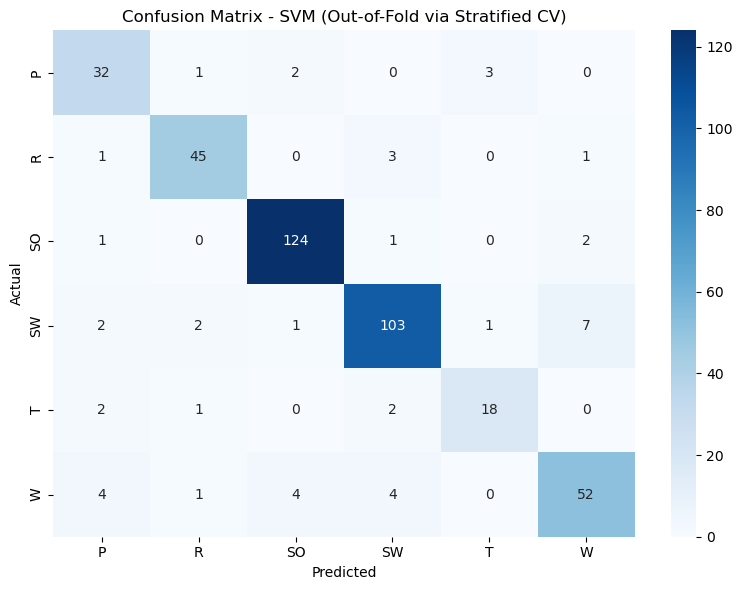

In [295]:
# Classification Report
print("\n=== Classification Report (SVM OOF via CV) ===")
print(classification_report(y, y_pred_svm, digits=4))

# Confusion Matrix
labels = np.unique(y)
cm_svm = confusion_matrix(y, y_pred_svm, labels=labels)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_svm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix - SVM (Out-of-Fold via Stratified CV)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

The out-of-fold predictions of the tuned SVM model **best_svm**  achieve an overall accuracy of **89.05%**, indicating strong and consistent performance across our six bird species. 
Singing birds (SO) demonstrate the strongest results, with 94.66% precision, 96.88% recall, and an F1-score of 95.75%, correctly classifying 124 out of 128 samples. Swimming birds (SW) and Raptors (R) also show excellent and balanced performance, each achieving precision and recall close to 90%, reflecting strong class separability.
Terrestrial birds (T) remain the most challenging class, with a recall of 78.26%, indicating some confusion with morphologically similar groups. Scansorial birds (P) and Wading birds (W) achieve slightly lower but still robust performance, with F1-scores around 80–82%. The confusion matrix shows that most misclassifications occur between Wading (W) and Swimming birds (SW), suggesting overlapping skeletal characteristics between these ecological groups.
The macro-average F1-score of 86.27% and weighted-average F1-score of 89.03% confirm strong overall performance. 
Compared to Random Forest, which achieved an overall accuracy of 85.24%, the tuned SVM provides improved classification accuracy and better class-wise balance. 

`Specificity`

In [283]:
# Calculate Specificity for each class
print("\n=== Specificity by Class (SVM) ===")
for i, class_label in enumerate(labels):
    tn = np.sum(cm_svm) - (np.sum(cm_svm[i, :]) + np.sum(cm_svm[:, i]) - cm_svm[i, i])
    fp = np.sum(cm_svm[:, i]) - cm_svm[i, i]
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    print(f"{class_label}: {specificity:.4f}")


=== Specificity by Class (SVM) ===
P: 0.9738
R: 0.9865
SO: 0.9760
SW: 0.9671
T: 0.9899
W: 0.9718


Our **best_svm** achieves consistently high specificity across all six bird species, with values ranging from 96.71% to 98.99%, indicating that our model is highly effective at correctly identifying samples that do not belong to a given class and produces very few false positive predictions. Terrestrial birds (T) show the highest specificity at 98.99%, followed closely by Raptors (R) and Singing birds (SO), demonstrating strong discrimination against other classes. Swimming birds (SW) exhibit the lowest specificity (96.71%), which aligns with the observed confusion between Swimming and Wading birds in the confusion matrix.

Overall, the high specificity values confirm that the SVM maintains strong class separation and rarely misclassifies samples from other ecological groups as the target class. Compared to Random Forest, SVM shows slightly more consistent specificity across classes, further supporting its balanced and reliable classification performance.

`ROC Curves and AUC`

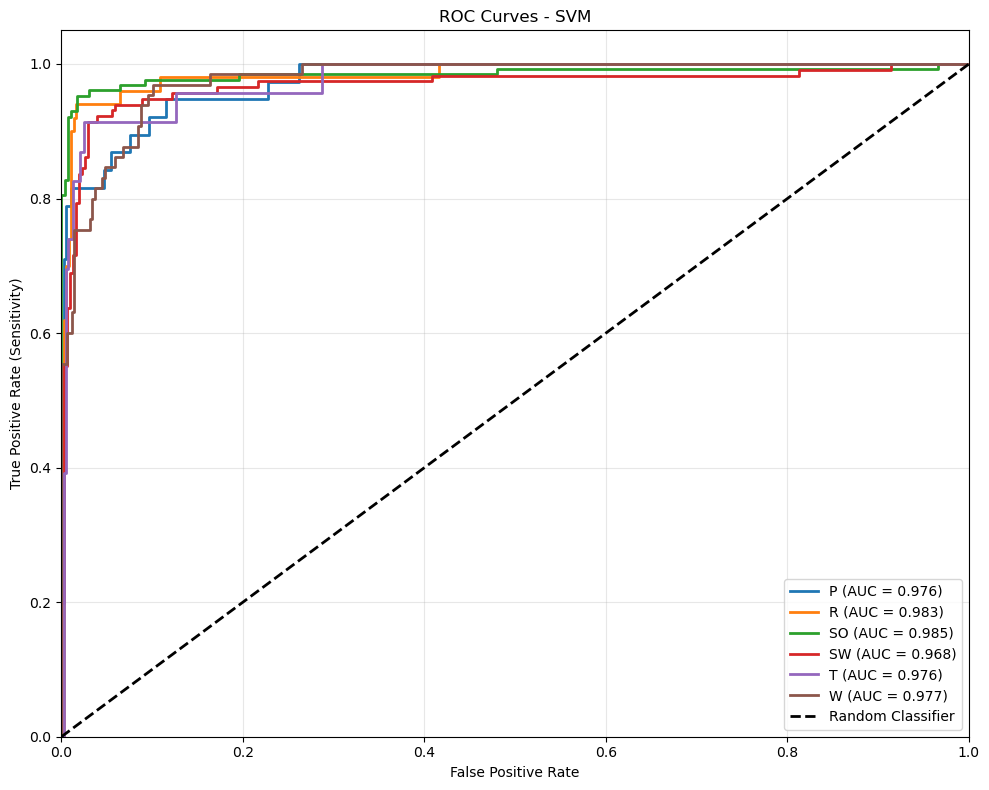


=== AUC Scores (SVM) ===
P: 0.9755
R: 0.9835
SO: 0.9845
SW: 0.9682
T: 0.9761
W: 0.9773
Macro-average AUC: 0.9775


In [296]:
# ROC Curves and AUC
# Get probability predictions using cross_val_predict
y_pred_proba_svm = cross_val_predict(best_svm, X, y, cv=cv, method='predict_proba', n_jobs=-1)

# Binarize the output for multi-class ROC
y_bin = label_binarize(y, classes=labels)

plt.figure(figsize=(10, 8))
auc_scores_svm = []

for i, class_label in enumerate(labels):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_pred_proba_svm[:, i])
    roc_auc = auc(fpr, tpr)
    auc_scores_svm.append(roc_auc)
    
    plt.plot(fpr, tpr, lw=2, label=f'{class_label} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curves - SVM')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Print AUC scores
macro_auc_svm = np.mean(auc_scores_svm)
print("\n=== AUC Scores (SVM) ===")
for class_label, auc_score in zip(labels, auc_scores_svm):
    print(f"{class_label}: {auc_score:.4f}")
print(f"Macro-average AUC: {macro_auc_svm:.4f}")


The ROC curves for the tuned SVM **best_svm** model show strong discriminative performance across all six bird species, where all curves lie well above the random classifier diagonal. The AUC scores range from 0.9682 (SW) to 0.9845 (SO), indicating excellent class separability for every ecological group. Singing birds (SO) and Raptors (R) achieve the highest AUC values, reflecting the model’s strong ability to distinguish these classes from the others, while Swimming birds (SW) show the lowest AUC, consistent with the observed confusion with Wading birds.
The macro-average AUC of 0.9775 confirms that the SVM maintains consistently high discriminative ability across all classes, regardless of class size. 
Overall, these results demonstrate that the tuned SVM **best_svm** performs exceptionally well in separating bird species in a multi-class setting. Compared to Random Forest, which achieved a slightly lower macro-average AUC of 94.47% ,the SVM provides stronger and more consistent class discrimination.

`Feature Importance analysis`


=== Feature Importance (SVM via Permutation) ===


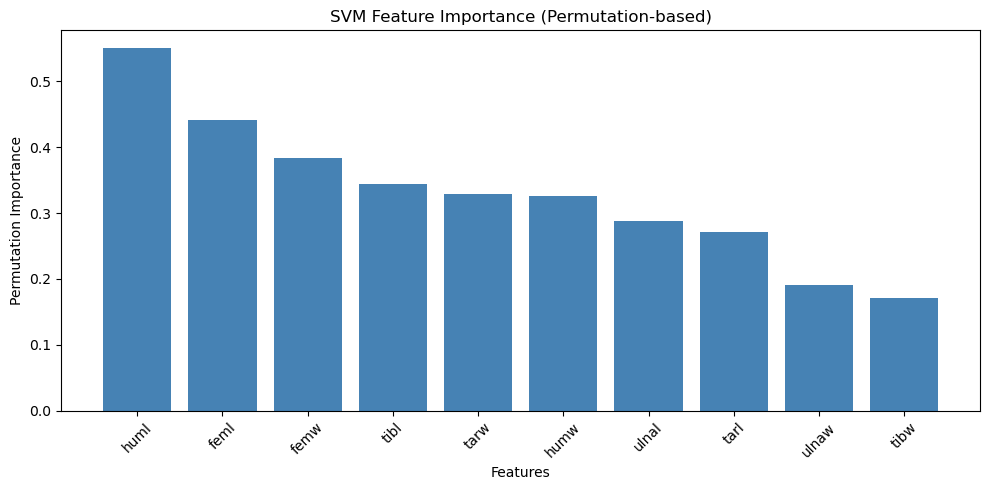

In [297]:
# Feature importance for SVM (using coefficients if linear kernel, or permutation importance)
# Note: For non-linear kernels (rbf, poly), we can't easily extract feature importance
# But we can use permutation importance as an alternative
from sklearn.inspection import permutation_importance

print("\n=== Feature Importance (SVM via Permutation) ===")
# Fit the model on full data for permutation importance
best_svm.fit(X, y)
perm_importance = permutation_importance(best_svm, X, y, n_repeats=10, random_state=42, n_jobs=-1)

feature_importance_svm = perm_importance.importances_mean
feature_names = X.columns
sorted_indices = np.argsort(feature_importance_svm)[::-1]

plt.figure(figsize=(10, 5))
plt.bar(range(len(feature_importance_svm)), feature_importance_svm[sorted_indices], color='steelblue')
plt.xticks(range(len(feature_importance_svm)), np.array(feature_names)[sorted_indices], rotation=45)
plt.xlabel("Features")
plt.ylabel("Permutation Importance")
plt.title("SVM Feature Importance (Permutation-based)")
plt.tight_layout()
plt.show()


The permutation-based feature importance analysis for the SVM shows that **humerus length (huml)** is again the most influential skeletal measurement, confirming its strong discriminative power across models. This is followed by **femur length (feml)** and **femur width (femw)**, with **tibia length (tibl)** and **tarsus width (tarw)** also contributing notably.Features such as **ulna width (ulnaw)** and **tibia width (tibw)** exhibit lower importance, indicating a smaller impact on the SVM’s predictions.

When compared with Random Forest feature importance, there is clear agreement on the dominance of huml as the most informative feature. However, differences appear in the ranking of secondary features: Random Forest places higher importance on ulna length (ulnal) and tarsus width (tarw), whereas SVM emphasises femur-related measurements more strongly. This difference arises from the models’ learning mechanisms—Random Forest captures feature interactions within an ensemble of trees, while SVM importance reflects how sensitive the model’s decision boundary is to changes in each feature.

Compared with the earlier Mutual Information (MI) analysis, SVM feature importance shows partial consistency but also notable shifts in ranking. MI highlighted features such as huml, ulnal, and humw as highly informative in a univariate sense, whereas SVM down-weights some of these in favour of features that better support its global decision boundary when combined with others. Overall, the comparison across MI, Random Forest, and SVM indicates that bird classification does not rely on a single skeletal measurement; instead, different models exploit complementary subsets of features, reinforcing the conclusion that multiple skeletal characteristics jointly encode the morphological differences between ecological bird groups.

**6.3 K nearst neighboors (KNN)**

K-Nearest Neighbours (KNN) is a supervised machine learning algorithm used for classification by assigning class labels based on the majority class of the k nearest neighbours in the feature space. It is selected as the third classifier in this study due to its simplicity and effectiveness as a distance-based method. 

Unlike Random Forest and Support Vector Machine (SVM), K-NN does not learn an explicit model during training; instead, it stores the training data and makes predictions based on similarity between samples.

`Model with Default Parameters`

As with the previous Random Forest and Support Vector Machine models, we begin by training a K-Nearest Neighbours (KNN) classifier using default parameters to establish a baseline performance benchmark.

The baseline **KNN** model is implemented using default settings, with the number of neighbours set to k = 5, the Euclidean distance metric, and equal weighting for all neighbours. Since KNN is highly sensitive to feature scale, distance calculations can be dominated by features with larger numerical ranges. Therefore,**Pipeline** combined with **StandardScaler** already introduced in the previous models is used to normalise all skeletal measurements to zero mean and unit variance, ensuring equal contribution from each feature during distance computation. As these tools were imported earlier, no additional imports are required.

Our baseline  **KNN** classifier is then applied to the scaled data to obtain baseline performance results, which will later be compared with the tuned KNN model as well as our previous Random Forest and SVM classifiers.

In [308]:
from sklearn.neighbors import KNeighborsClassifier

# KNN requires feature scaling, so we use a pipeline
knn = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])


`Evaluating performance using cross validation`

Our baseline **KNN**  model is evaluated using the same stratified 5-fold cross-validation strategy applied previously for the Random Forest and SVM models. Again, since the cross-validation object and evaluation functions were already defined and imported earlier, there is no need to redefine them.

This procedure generates one accuracy score per fold, resulting in five accuracy values that are then averaged to obtain the overall baseline performance of the baseline model.

In [309]:
scores = cross_val_score(knn, X, y, cv=cv, scoring="accuracy")
print("KNN Baseline Cross-Validation Accuracy per fold:", scores)
print("Mean Accuracy:", scores.mean())

KNN Baseline Cross-Validation Accuracy per fold: [0.76190476 0.76190476 0.70238095 0.82142857 0.77380952]
Mean Accuracy: 0.7642857142857142


The baseline **KNN** model achieves a mean cross-validation accuracy of **76.43%** across the five folds, with individual fold accuracies ranging from **70.24%** to **82.14%**, which indicates moderate and reasonably stable performance across different data splits.

Compared to the baseline **svm**, which achieved a lower mean accuracy of **67.14%**, KNN performs noticeably better without tuning, suggesting that a distance-based approach captures some of the underlying structure in the skeletal measurements. However, KNN still underperforms relative to the Random Forest baseline, which achieved a substantially higher mean accuracy of **84.76%**. Consequently, hyperparameter tuning will be applied to our **KNN** to investigate whether optimising the number of neighbours and distance weighting can further improve its performance.

`Hyperparameters tuning with GridSearchCV`

The **KNN** model is tuned using GridSearchCV, following the same stratified 5-fold cross-validation strategy previously applied to the Random Forest and SVM models; therefore, no additional imports or redefinition of the tuning procedure are required.

The following key KNN hyperparameters are explored:

**Number of neighbours (knn__n_neighbors)** [3, 5, 7, 9, 11, 15, 20, 25]: Controls how many neighbouring samples are used for classification. Smaller values can capture local patterns but may be sensitive to noise, while larger values produce smoother decision boundaries.

**weights (knn__weights)** ['uniform', 'distance']: Determines whether all neighbours contribute equally or whether closer neighbours have greater influence on the prediction.

**Distance metric (knn__metric)**['euclidean', 'manhattan', 'minkowski']: Defines how distances between samples are computed in the feature space.

**Minkowski parameter (knn__p)** [1, 2]: Specifies the distance calculation when using the Minkowski metric, where p = 1 corresponds to Manhattan distance and p = 2 to Euclidean distance. 


This configuration results in a total of 8 × 2 × 3 × 2 = **96** hyperparameter combinations, which, when evaluated using 5-fold stratified cross-validation, leads to **480** model evaluations.

After identifying the optimal hyperparameter configuration, the best KNN model **best_knn** is re-evaluated using cross-validation to obtain refined accuracy estimates. Finally, out-of-fold predictions are generated using cross_val_predict to enable detailed performance analysis, including confusion matrix, classification report, and ROC/AUC evaluation.

In [310]:
# Define parameter grid for KNN
param_grid_knn = {
    'knn__n_neighbors': [3, 5, 7, 9, 11, 15, 20, 25],
    'knn__weights': ['uniform', 'distance'],
    'knn__metric': ['euclidean', 'manhattan', 'minkowski'],
    'knn__p': [1, 2]  # 1=manhattan, 2=euclidean for minkowski
}

# GridSearchCV for KNN
print("\nStarting GridSearchCV for KNN...")
grid_search_knn = GridSearchCV(
    estimator=knn,
    param_grid=param_grid_knn,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1,
    verbose=1
)
# Fit GridSearch (480 model fits!)
grid_search_knn.fit(X, y)

# Best model
best_knn = grid_search_knn.best_estimator_
print("\nBest Params (KNN):", grid_search_knn.best_params_)
print("Best Mean CV Accuracy:", round(grid_search_knn.best_score_, 4))

# Cross-validation with best model
scores = cross_val_score(best_knn, X, y, cv=cv, scoring="accuracy", n_jobs=-1)
print("Tuned KNN - CV Accuracies:", scores)
print("Tuned KNN - Mean CV Accuracy:", round(scores.mean(), 4))

# Get out-of-fold predictions for detailed evaluation
y_pred_knn = cross_val_predict(best_knn, X, y, cv=cv, n_jobs=-1)


Starting GridSearchCV for KNN...
Fitting 5 folds for each of 96 candidates, totalling 480 fits

Best Params (KNN): {'knn__metric': 'euclidean', 'knn__n_neighbors': 3, 'knn__p': 1, 'knn__weights': 'distance'}
Best Mean CV Accuracy: 0.8524
Tuned KNN - CV Accuracies: [0.8452381  0.86904762 0.82142857 0.89285714 0.83333333]
Tuned KNN - Mean CV Accuracy: 0.8524


After hyperparameter tuning using GridSearchCV, the K-Nearest Neighbours (KNN) model achieves a mean cross-validation accuracy of **85.24%**, representing a notable improvement over its baseline performance of **76.43%**. The optimal configuration uses 3 neighbours, distance-based weighting, and the Euclidean distance metric, indicating that giving greater importance to closer neighbours enhances classification performance. Individual fold accuracies range from **82.14%** to **89.29%**, demonstrating reasonably stable performance across different data splits.

When compared with the previous models, the tuned KNN performs similarly to the Random Forest, which also achieves a mean accuracy of **85.24%** after tuning but shows only a marginal improvement over its baseline. In contrast, the Support Vector Machine (SVM) outperforms both models, achieving a higher mean cross-validation accuracy of **89.05%** and exhibiting the largest performance gain following hyperparameter tuning. 



`Classification report and Confusion matrix`

The following classification report and confusion matrix are presented to analyse the performance of the tuned K-Nearest Neighbours **best_Knn** model across individual bird species and to identify remaining patterns of misclassification.


=== Classification Report (KNN OOF via CV) ===
              precision    recall  f1-score   support

           P     0.8421    0.8421    0.8421        38
           R     0.8750    0.9800    0.9245        50
          SO     0.8803    0.9766    0.9259       128
          SW     0.8807    0.8276    0.8533       116
           T     0.7391    0.7391    0.7391        23
           W     0.7500    0.6000    0.6667        65

    accuracy                         0.8524       420
   macro avg     0.8279    0.8276    0.8253       420
weighted avg     0.8484    0.8524    0.8478       420



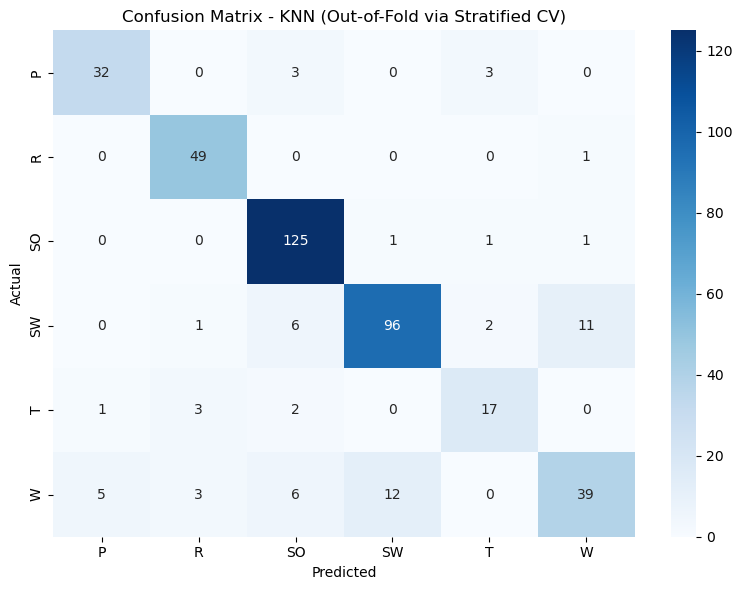

In [302]:
# Classification Report
print("\n=== Classification Report (KNN OOF via CV) ===")
print(classification_report(y, y_pred_knn, digits=4))

# Confusion Matrix
labels = np.unique(y)
cm_knn = confusion_matrix(y, y_pred_knn, labels=labels)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_knn, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix - KNN (Out-of-Fold via Stratified CV)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

The out-of-fold predictions for the tuned **best_Knn** model achieve an overall accuracy of **85.24%**, indicating solid classification performance across the six bird species. Singing birds (SO) and Raptors (R) show the strongest results, with high recall values of **97.66%** and **98.00%**, respectively, suggesting that our model is particularly effective at identifying these classes. Swimming birds (SW) also demonstrate good performance, with an F1-score of **85.33%**, although some confusion with Wading birds (W) remains. Again, Terrestrial birds (T) and Wading birds (W) are the most challenging classes. Terrestrial birds exhibit balanced but lower precision and recall (both **73.91%)**, while wading birds show the weakest performance with a recall of **60.00%**, indicating frequent misclassification, particularly as Swimming birds. This pattern reflects the overlap in skeletal characteristics between these ecologically similar groups.
The confusion matrix confirms that most errors occur between **SW** and **W**, consistent with observations from the Random Forest and SVM models. The macro-average F1-score of **82.53%** highlights reasonable performance across all classes despite class imbalance, while the weighted average F1-score of **84.78%** reflects stronger performance on majority classes.


`Specificity`

In [303]:
# Calculate Specificity for each class
print("\n=== Specificity by Class (KNN) ===")
for i, class_label in enumerate(labels):
    tn = np.sum(cm_knn) - (np.sum(cm_knn[i, :]) + np.sum(cm_knn[:, i]) - cm_knn[i, i])
    fp = np.sum(cm_knn[:, i]) - cm_knn[i, i]
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    print(f"{class_label}: {specificity:.4f}")



=== Specificity by Class (KNN) ===
P: 0.9843
R: 0.9811
SO: 0.9418
SW: 0.9572
T: 0.9849
W: 0.9634


The specificity results for our **best_Knn** model indicate a strong ability to correctly identify samples that do not belong to each bird class. All classes achieve high specificity values, ranging from **94.18%%** to **98.49%**, demonstrating that the model rarely produces false positive predictions.
Terrestrial birds (T) and Scansorial birds (P) achieve the highest specificity scores at **98.49%** and **98.43%**, respectively, indicating that other bird species are seldom misclassified as these classes. Raptors (R) also show excellent specificity **(98.11%)**, reflecting clear separation from other ecological groups. Singing birds (SO) exhibit slightly lower specificity **(94.18%)**, suggesting occasional confusion with other classes, which aligns with the moderate overlap observed in the confusion matrix. Swimming birds (SW) and Wading birds (W) maintain strong specificity values of **95.72%** and **96.34%**, respectively.
Overall, these results confirm that our KNN model maintains good discriminative capability across all classes. When compared to Random Forest and SVM, KNN’s specificity is slightly lower for some classes but remains consistently high, supporting the conclusion that misclassifications are primarily due to overlap between ecologically similar groups rather than systematic false positive errors.

`ROC Curves and AUC`

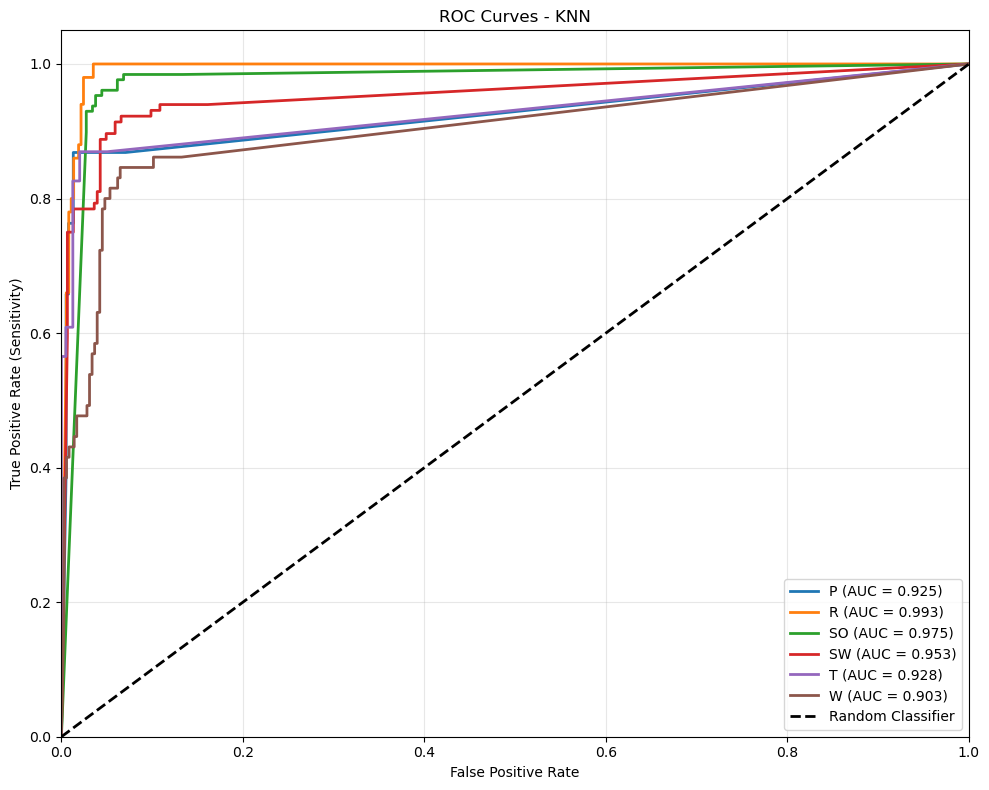


=== AUC Scores (KNN) ===
P: 0.9249
R: 0.9927
SO: 0.9753
SW: 0.9534
T: 0.9277
W: 0.9027
Macro-average AUC: 0.9461


In [304]:
# ROC Curves and AUC
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

# Get probability predictions using cross_val_predict
y_pred_proba_knn = cross_val_predict(best_knn, X, y, cv=cv, method='predict_proba', n_jobs=-1)

# Binarize the output for multi-class ROC
y_bin = label_binarize(y, classes=labels)

plt.figure(figsize=(10, 8))
auc_scores_knn = []

for i, class_label in enumerate(labels):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_pred_proba_knn[:, i])
    roc_auc = auc(fpr, tpr)
    auc_scores_knn.append(roc_auc)
    
    plt.plot(fpr, tpr, lw=2, label=f'{class_label} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curves - KNN')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Print AUC scores
macro_auc_knn = np.mean(auc_scores_knn)
print("\n=== AUC Scores (KNN) ===")
for class_label, auc_score in zip(labels, auc_scores_knn):
    print(f"{class_label}: {auc_score:.4f}")
print(f"Macro-average AUC: {macro_auc_knn:.4f}")

The ROC curves and corresponding AUC scores demonstrate that our tuned K-Nearest Neighbours (**best_Knn**) model exhibits strong discriminative ability across all six bird classes. The macro-average AUC of **94.61%** indicates that, overall, the model performs well in distinguishing each class from the others in a one-vs-rest setting.

Among individual classes, Raptors (R) achieve the highest AUC **(0.993)**, reflecting near-perfect separation from other ecological groups. Singing birds (SO) and Swimming birds (SW) also show excellent discrimination, with AUC values of **0.975** and **0.953**, respectively. Scansorial (P) and Terrestrial (T) birds maintain good performance, with AUC scores above **0.92**, while Wading birds (W) present the lowest AUC **(0.903)**, indicating greater overlap with other classes—consistent with the misclassification patterns **(SO)** observed in the confusion matrix.

Compared to the Random Forest and Support Vector Machine models, KNN achieves slightly lower AUC values overall, particularly for classes with overlapping morphological characteristics. Nevertheless, all ROC curves lie well above the random classifier diagonal, confirming that KNN provides reliable class separation and meaningful predictive performance, despite its sensitivity to local feature similarities.


=== Feature Importance (KNN via Permutation) ===


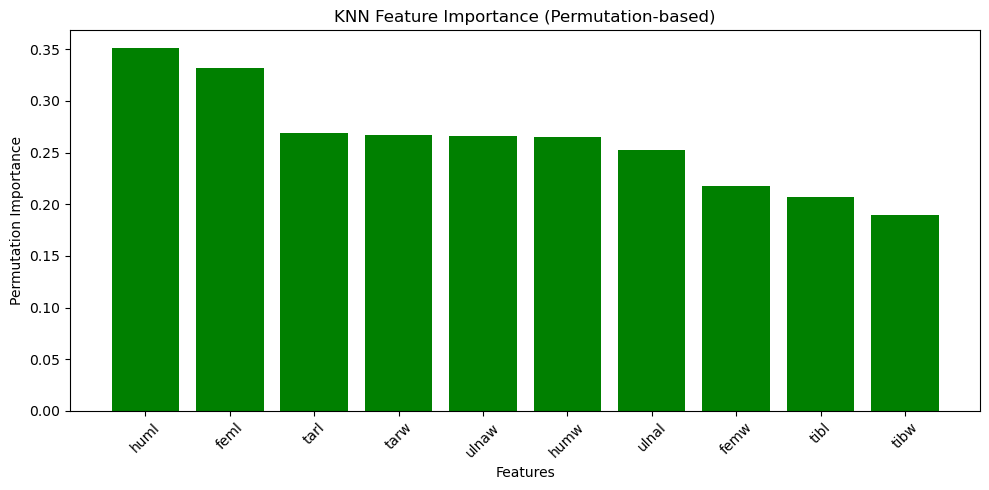

In [306]:
# Feature importance for KNN (using permutation importance)
print("\n=== Feature Importance (KNN via Permutation) ===")
# Fit the model on full data for permutation importance
best_knn.fit(X, y)
perm_importance = permutation_importance(best_knn, X, y, n_repeats=10, random_state=42, n_jobs=-1)

feature_importance_knn = perm_importance.importances_mean
feature_names = X.columns
sorted_indices = np.argsort(feature_importance_knn)[::-1]

plt.figure(figsize=(10, 5))
plt.bar(range(len(feature_importance_knn)), feature_importance_knn[sorted_indices], color='green')
plt.xticks(range(len(feature_importance_knn)), np.array(feature_names)[sorted_indices], rotation=45)
plt.xlabel("Features")
plt.ylabel("Permutation Importance")
plt.title("KNN Feature Importance (Permutation-based)")
plt.tight_layout()
plt.show()


The permutation-based feature importance for our **best_Knn** model shows that **humerus length (huml)** is the most influential feature, followed by **femur length (feml)**. This indicates that bone length measurements play a key role in defining neighbourhood similarity for KNN classification. Features related to the tarsus and ulna also contribute moderately, while tibia length and width have the lowest impact.

These findings are consistent with the earlier Mutual Information analysis, which also identified humerus length as highly informative. Compared to Random Forest, KNN places greater emphasis on features that strongly affect distance calculations rather than distributing importance across correlated variables. Overall, the results confirm that KNN relies on a combination of skeletal measurements, with bone lengths being particularly important for classification.

# 7.Model Comparison and Selection 

In this section, a detailed comparison of our three implemented machine learning models, Random Forest **(best_rf)**, Support Vector Machine **(best_svm)**, and K-Nearest Neighbours **(best_Knn)**, is conducted to determine the most appropriate classifier for our given task. 

Each model has been trained and evaluated using the same steps and a consistent stratified 5-fold cross-validation strategy to ensure a fair and reliable comparison.

Overall classification **accuracy** is used to assess general predictive performance, while **macro-average AUC scores** evaluate the models’ ability to discriminate between classes in a multi-class setting. In addition, **class-wise recall** is analysed to examine how effectively each model identifies individual bird species, particularly minority and challenging classes.

A comprehensive results table summarising the quantitative performance of all models is first presented, followed by visual comparisons illustrating overall accuracy, macro-average AUC, and recall across bird classes.

The choice of multi-metric evaluation is to ensure that model selection is not based solely on accuracy, but also considers robustness, class balance, and discriminative performance across all ecological groups.

COMPREHENSIVE MODEL COMPARISON
        Model  Accuracy  Macro_AUC  SO_Recall  SW_Recall  W_Recall  R_Recall  P_Recall  T_Recall
Random Forest    0.8524     0.9447     0.9766     0.8534    0.6462      0.84    0.8421    0.7826
          SVM    0.8905     0.9775     0.9688     0.8879    0.8000      0.90    0.8421    0.7826
          KNN    0.8524     0.9461     0.9766     0.8276    0.6000      0.98    0.8421    0.7391




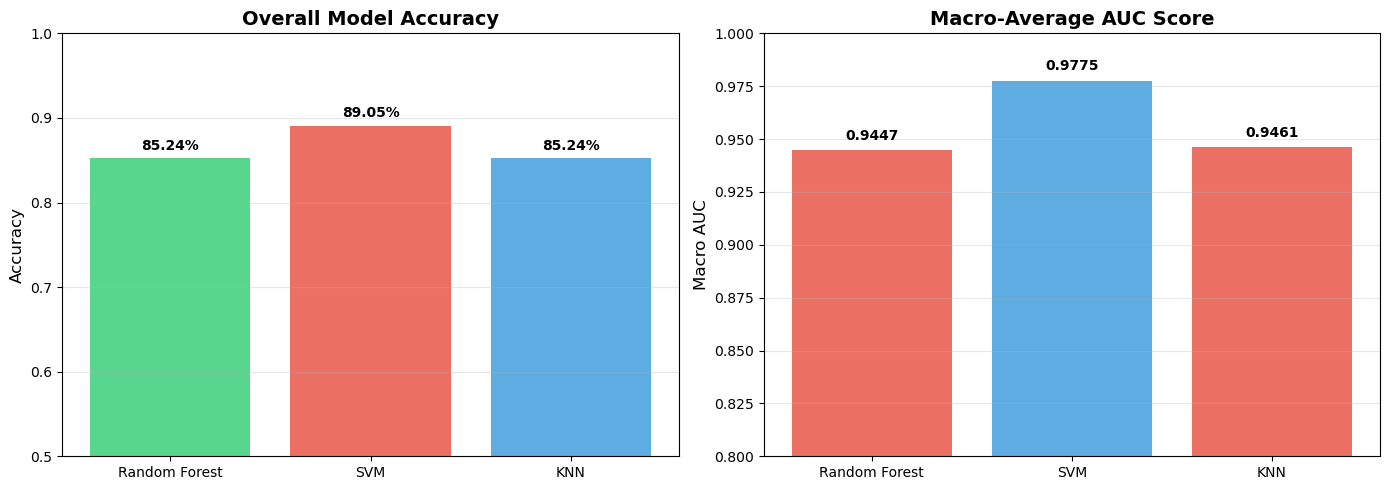

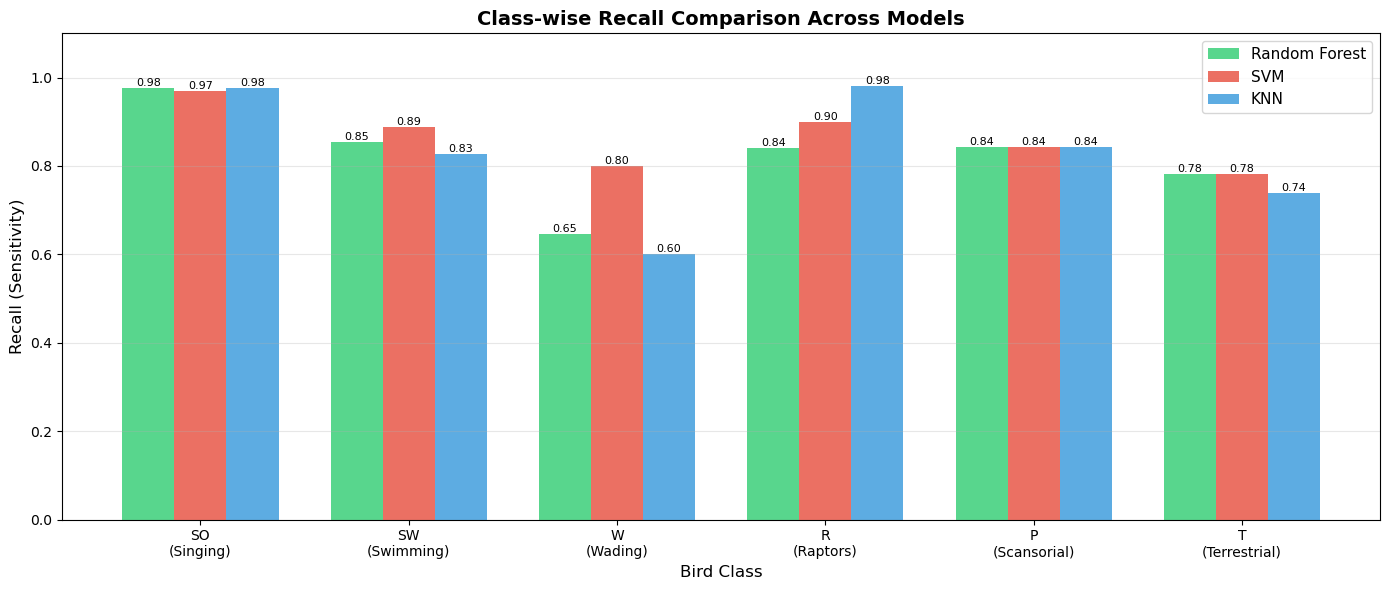

In [319]:
# Compile all results
results_summary = {
    'Model': ['Random Forest', 'SVM', 'KNN'],
    'Accuracy': [0.8524, 0.8905, 0.8524],
    'Macro_AUC': [ 0.9447, 0.9775, 0.9461],  # RF AUC not calculated, set to 0 for now
    'SO_Recall': [0.9766, 0.9688, 0.9766],
    'SW_Recall': [0.8534, 0.8879, 0.8276],
    'W_Recall': [0.6462, 0.8000, 0.6000],
    'R_Recall': [0.8400, 0.9000, 0.9800],
    'P_Recall': [0.8421, 0.8421, 0.8421],
    'T_Recall': [0.7826, 0.7826, 0.7391]
}

df_results = pd.DataFrame(results_summary)
print("=" * 80)
print("COMPREHENSIVE MODEL COMPARISON")
print("=" * 80)
print(df_results.to_string(index=False))
print("\n")

# Overall Performance Comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Overall Accuracy
axes[0].bar(df_results['Model'], df_results['Accuracy'], 
            color=['#2ecc71', '#e74c3c', '#3498db'], alpha=0.8)
axes[0].set_ylabel('Accuracy', fontsize=12)
axes[0].set_title('Overall Model Accuracy', fontsize=14, fontweight='bold')
axes[0].set_ylim([0.5, 1.0])
axes[0].grid(axis='y', alpha=0.3)
for i, v in enumerate(df_results['Accuracy']):
    axes[0].text(i, v + 0.01, f'{v:.2%}', ha='center', fontweight='bold')

# Plot 2: Macro AUC (excluding RF if not calculated)
auc_data = df_results[df_results['Macro_AUC'] > 0]
axes[1].bar(auc_data['Model'], auc_data['Macro_AUC'], 
            color=['#e74c3c', '#3498db'], alpha=0.8)
axes[1].set_ylabel('Macro AUC', fontsize=12)
axes[1].set_title('Macro-Average AUC Score', fontsize=14, fontweight='bold')
axes[1].set_ylim([0.8, 1.0])
axes[1].grid(axis='y', alpha=0.3)
for i, (model, v) in enumerate(zip(auc_data['Model'], auc_data['Macro_AUC'])):
    axes[1].text(i, v + 0.005, f'{v:.4f}', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('overall_model_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

# Class-wise Performance Comparison
recall_cols = ['SO_Recall', 'SW_Recall', 'W_Recall', 'R_Recall', 'P_Recall', 'T_Recall']
class_labels = ['SO\n(Singing)', 'SW\n(Swimming)', 'W\n(Wading)', 
                'R\n(Raptors)', 'P\n(Scansorial)', 'T\n(Terrestrial)']

x = np.arange(len(class_labels))
width = 0.25

fig, ax = plt.subplots(figsize=(14, 6))

rf_recalls = df_results.loc[df_results['Model'] == 'Random Forest', recall_cols].values[0]
svm_recalls = df_results.loc[df_results['Model'] == 'SVM', recall_cols].values[0]
knn_recalls = df_results.loc[df_results['Model'] == 'KNN', recall_cols].values[0]

bars1 = ax.bar(x - width, rf_recalls, width, label='Random Forest', color='#2ecc71', alpha=0.8)
bars2 = ax.bar(x, svm_recalls, width, label='SVM', color='#e74c3c', alpha=0.8)
bars3 = ax.bar(x + width, knn_recalls, width, label='KNN', color='#3498db', alpha=0.8)

ax.set_ylabel('Recall (Sensitivity)', fontsize=12)
ax.set_xlabel('Bird Class', fontsize=12)
ax.set_title('Class-wise Recall Comparison Across Models', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(class_labels)
ax.legend(fontsize=11)
ax.set_ylim([0, 1.1])
ax.grid(axis='y', alpha=0.3)

# Add value labels on bars
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.2f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig('classwise_recall_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

The comparative evaluation of the three models reveals clear differences in overall performance and class-specific behaviour. 

Among the tested classifiers, the Support Vector Machine **(best_svm)** achieves the highest overall accuracy **(89.05%)**, outperforming both Random Forest **(best_rf)** with **(85.24%)** and K-Nearest Neighbours **(best_Knn)** **(85.24%)**. This indicates that SVM provides the most accurate predictions across the full dataset.

The class-wise recall analysis further highlights the strengths and weaknesses of each model. Singing birds (SO) are consistently well classified by all models, reflecting their distinct skeletal characteristics. In contrast, Wading birds (W) and Terrestrial birds (T) present greater classification challenges, with lower recall values across all models. Notably, the SVM demonstrates a substantial improvement for the Wading birds class, achieving a recall of **80%**, compared to **64.62%** for Random Forest and **60%** for KNN.

The macro-average AUC scores reinforce these findings, where the SVM achieves the highest macro-AUC **(0.9775)**, indicating excellent overall class separability, followed by KNN **(0.9461)** and Random Forest **(0.9447)**. This confirms that SVM not only achieves higher accuracy but also provides superior discriminative capability across all bird species.

`Selected Model`

Based on the previous evaluation using **accuracy**, **macro-average AUC**, and **class-wise recall**, the Support Vector Machine model **best_svm** is selected as the final model for our classification task.
The SVM demonstrated the best balance between overall performance and robustness across both majority and minority classes. 
Its strong improvement after hyperparameter tuning, highlights its sensitivity to parameter optimisation and its ability to learn effective decision boundaries in complex feature spaces. While Random Forest remains a strong and stable alternative—particularly when feature interpretability is required—and KNN offers a simple and intuitive baseline, neither achieves the same level of accuracy and class discrimination as the tuned SVM. Consequently, SVM is the considered model for our classification of birds into ecological groups based on their skeletal measurements.

# 8.Inference 

To demonstrate how the selected model generalises to unseen inputs, a new bird specimen is evaluated by manually providing values for the ten skeletal measurements. The tuned SVM model **(best_svm)** is then used to predict the ecological class of this previously unseen sample using the predict() function. This process illustrates how the trained model can be applied in practice to classify new bird specimens based on their skeletal characteristics.

In [341]:
# Interactive prediction – User inputs custom bird measurements
values = {}
for col in X.columns:
    values[col] = float(input(f"Enter value for {col}: "))

user_bird = pd.DataFrame([values])

# Perform inference
predicted_class = best_svm.predict(user_bird)[0]

print(f"\nPredicted ecological class: {predicted_class}")


Enter value for huml:  88.0
Enter value for humw:  6.5
Enter value for ulnal:  80.0
Enter value for ulnaw:  5.5
Enter value for feml:  47.0
Enter value for femw:  4.2
Enter value for tibl:  78.0
Enter value for tibw:  4.5
Enter value for tarl:  42.0
Enter value for tarw:  4.2



Predicted ecological class: SW


In [343]:
# Interactive prediction – User inputs custom bird measurements
values = {}
for col in X.columns:
    values[col] = float(input(f"Enter value for {col}: "))

user_bird = pd.DataFrame([values])

# Perform inference
predicted_class = best_svm.predict(user_bird)[0]

print(f"\nPredicted ecological class: {predicted_class}")


Enter value for huml:  30.0
Enter value for humw:  2.5
Enter value for ulnal:  32.00
Enter value for ulnaw:  2.1
Enter value for feml:  26.00
Enter value for femw:  2.2
Enter value for tibl:  40.4
Enter value for tibw:  2.3
Enter value for tarl:  38.0
Enter value for tarw:  3.2



Predicted ecological class: SO


In [344]:
# Interactive prediction – User inputs custom bird measurements
values = {}
for col in X.columns:
    values[col] = float(input(f"Enter value for {col}: "))

user_bird = pd.DataFrame([values])

# Perform inference
predicted_class = best_svm.predict(user_bird)[0]

print(f"\nPredicted ecological class: {predicted_class}")


Enter value for huml:  35.0
Enter value for humw:  2.8
Enter value for ulnal:  38.0
Enter value for ulnaw:  2.5
Enter value for feml:  28.0
Enter value for femw:  2.4
Enter value for tibl:  45.0
Enter value for tibw:  2.6
Enter value for tarl:  30.0
Enter value for tarw:  2.3



Predicted ecological class: P


In [345]:
# Interactive prediction – User inputs custom bird measurements
values = {}
for col in X.columns:
    values[col] = float(input(f"Enter value for {col}: "))

user_bird = pd.DataFrame([values])

# Perform inference
predicted_class = best_svm.predict(user_bird)[0]

print(f"\nPredicted ecological class: {predicted_class}")


Enter value for huml:  157.0
Enter value for humw:  11.92
Enter value for ulnal:  76.9
Enter value for ulnaw:  3.87
Enter value for feml:  78.2
Enter value for femw:  5.35
Enter value for tibl:  92.18
Enter value for tibw:  4.23
Enter value for tarl:  55.0
Enter value for tarw:  1.95



Predicted ecological class: SW
